In [22]:
import json
import time
from pathlib import Path
from itertools import combinations
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from tqdm import tqdm

DATA_DIR = Path("data")
if not DATA_DIR.exists():
    DATA_DIR = Path("forth_task/data")
OUTPUT_DIR = DATA_DIR.parent / "outputs/candidates"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
rng = np.random.default_rng(42)
train_paths = sorted((DATA_DIR / "photos/train").glob("*.jpg"))
val_paths = sorted((DATA_DIR / "photos/val").glob("*.jpg"))
sample_paths = sorted(rng.choice(train_paths, size=100, replace=False))
PADDING = (0, 0.12)
MAX_LINES = 150
IOU_THRESHOLD = 0.33


In [23]:
def read_image(path):
    return cv2.cvtColor(cv2.imread(str(path)), cv2.COLOR_BGR2RGB)


def sign_boxes(path):
    label = DATA_DIR / "labels" / path.parent.name / f"{path.stem}.json"
    objects = json.loads(label.read_text())["frames"][0]["objects"]
    return np.asarray([
        [obj["box2d"][k] for k in ("x1", "y1", "x2", "y2")]
        for obj in objects
        if obj["category"] == "traffic sign" and "box2d" in obj
        and obj["box2d"]["x2"] > obj["box2d"]["x1"]
        and obj["box2d"]["y2"] > obj["box2d"]["y1"]
    ], dtype=float).reshape(-1, 4)


def iou(box, boxes):
    intersection = np.prod(np.maximum(0, np.minimum(box[2:], boxes[:, 2:]) -
                                      np.maximum(box[:2], boxes[:, :2])), axis=1)
    area = np.prod(box[2:] - box[:2])
    areas = np.prod(boxes[:, 2:] - boxes[:, :2], axis=1)
    return intersection / (area + areas - intersection + 1e-9)

In [24]:
def rectangles_to_boxes(rectangles, image):
    height, width = image.shape[:2]
    boxes = set()
    for x, y, w, h in rectangles:
        if 4 <= w <= width * 0.6 and 6 <= h <= height * 0.6 and 0.2 <= w/h <= 6:
            for padding in PADDING:
                dx, dy = round(w * padding), round(h * padding)
                boxes.add((max(0, x-dx), max(0, y-dy),
                           min(width, x+w+dx), min(height, y+h+dy)))
    return np.asarray(sorted(boxes), dtype=float).reshape(-1, 4)


def hsv_candidates(image):
    hsv = cv2.cvtColor(image, cv2.COLOR_RGB2HSV)
    masks = [
        cv2.inRange(hsv, (0, 70, 45), (12, 255, 255)) |
        cv2.inRange(hsv, (165, 70, 45), (179, 255, 255)),
        cv2.inRange(hsv, (15, 60, 45), (40, 255, 255)),
        cv2.inRange(hsv, (40, 55, 35), (140, 255, 255)),
        cv2.inRange(hsv, (0, 0, 150), (179, 65, 255))
    ]
    rectangles = []
    for mask in masks:
        mask = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, np.ones((3, 3), np.uint8))
        contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
        rectangles.extend(cv2.boundingRect(contour) for contour in contours)
    return rectangles_to_boxes(rectangles, image)


def mser_candidates(image):
    mser = cv2.MSER_create()
    mser.setMinArea(30)
    mser.setMaxArea(int(image.shape[0] * image.shape[1] * 0.08))
    _, regions = mser.detectRegions(cv2.cvtColor(image, cv2.COLOR_RGB2GRAY))
    return rectangles_to_boxes(regions, image)


def shape_candidates(image):
    gray = cv2.cvtColor(image, cv2.COLOR_RGB2GRAY)
    gray = cv2.GaussianBlur(gray, (3, 3), 0)
    rectangles = []
    for low, high in [(30, 90), (70, 180)]:
        edges = cv2.Canny(gray, low, high)
        edges = cv2.morphologyEx(edges, cv2.MORPH_CLOSE, np.ones((3, 3), np.uint8))
        contours, _ = cv2.findContours(edges, cv2.RETR_LIST, cv2.CHAIN_APPROX_SIMPLE)
        for contour in contours:
            area = cv2.contourArea(contour)
            perimeter = cv2.arcLength(contour, True)
            if area < 20 or perimeter == 0:
                continue
            polygon = cv2.approxPolyDP(contour, 0.03 * perimeter, True)
            circularity = 4 * np.pi * area / perimeter**2
            if cv2.isContourConvex(polygon) and (len(polygon) in (3, 4, 8) or circularity >= 0.7):
                rectangles.append(cv2.boundingRect(contour))
    return rectangles_to_boxes(rectangles, image)


def line_candidates(image):
    gray = cv2.cvtColor(image, cv2.COLOR_RGB2GRAY)
    edges = cv2.Canny(gray, 40, 120)
    lines = cv2.HoughLinesP(edges, 1, np.pi/180, threshold=12,
                            minLineLength=8, maxLineGap=5)
    if lines is None:
        return np.empty((0, 4))
    segments = np.asarray(lines, dtype=float).reshape(-1, 4)
    vectors = segments[:, 2:] - segments[:, :2]
    lengths = np.linalg.norm(vectors, axis=1)
    order = np.argsort(lengths)[::-1][:MAX_LINES]
    segments, lengths = segments[order], lengths[order]
    rectangles = []
    for i, j in combinations(range(len(segments)), 2):
        first, second = segments[i].reshape(2, 2), segments[j].reshape(2, 2)
        direction = (first[1] - first[0]) / lengths[i]
        other = (second[1] - second[0]) / lengths[j]
        if abs(np.dot(direction, other)) < np.cos(np.deg2rad(10)):
            continue
        normal = np.array([-direction[1], direction[0]])
        distance = abs(np.dot(second.mean(axis=0) - first.mean(axis=0), normal))
        a, b = np.sort(first @ direction), np.sort(second @ direction)
        overlap = min(a[1], b[1]) - max(a[0], b[0])
        if 4 <= distance <= 250 and overlap >= 0.5 * min(lengths[i], lengths[j]):
            points = np.vstack([first, second]).astype(np.float32)
            rectangles.append(cv2.boundingRect(points))
    return rectangles_to_boxes(rectangles, image)


def merge_boxes(*groups):
    return np.unique(np.concatenate(groups, axis=0), axis=0)


def contrast_candidates(image):
    lab = cv2.cvtColor(image, cv2.COLOR_RGB2LAB)
    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
    lab[:, :, 0] = clahe.apply(lab[:, :, 0])
    enhanced = cv2.cvtColor(lab, cv2.COLOR_LAB2RGB)
    return merge_boxes(hsv_candidates(enhanced), mser_candidates(enhanced),
                       shape_candidates(enhanced))


def adaptive_candidates(image):
    gray = cv2.cvtColor(image, cv2.COLOR_RGB2GRAY)
    gray = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8)).apply(gray)
    rectangles = []
    for block_size in (15, 31):
        for mode in (cv2.THRESH_BINARY, cv2.THRESH_BINARY_INV):
            mask = cv2.adaptiveThreshold(gray, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
                                         mode, block_size, 5)
            for kernel in ((1, 1), (9, 3), (3, 9)):
                joined = cv2.morphologyEx(mask, cv2.MORPH_CLOSE,
                                         np.ones((kernel[1], kernel[0]), np.uint8))
                contours, _ = cv2.findContours(joined, cv2.RETR_LIST, cv2.CHAIN_APPROX_SIMPLE)
                for contour in contours:
                    x, y, w, h = cv2.boundingRect(contour)
                    fill = cv2.contourArea(contour) / max(w*h, 1)
                    if 0.15 <= fill <= 1 and w*h >= 20:
                        rectangles.append((x, y, w, h))
    return rectangles_to_boxes(rectangles, image)


def grouped_candidates(image, boxes):
    widths = boxes[:, 2] - boxes[:, 0]
    heights = boxes[:, 3] - boxes[:, 1]
    boxes = boxes[(widths <= 160) & (heights <= 100)]
    boxes = boxes[np.argsort(boxes[:, 0])]
    rectangles = []
    for i, first in enumerate(boxes):
        w1, h1 = first[2:] - first[:2]
        for second in boxes[i+1:]:
            if second[0] > first[2] + max(15, h1*2):
                break
            w2, h2 = second[2:] - second[:2]
            vertical_overlap = min(first[3], second[3]) - max(first[1], second[1])
            horizontal_overlap = min(first[2], second[2]) - max(first[0], second[0])
            horizontal_gap = max(0, second[0]-first[2])
            vertical_gap = max(0, max(first[1], second[1])-min(first[3], second[3]))
            aligned_row = (vertical_overlap >= 0.5*min(h1,h2)
                           and 0.4 <= h1/h2 <= 2.5
                           and horizontal_gap <= max(8, min(h1,h2)))
            aligned_column = (horizontal_overlap >= 0.5*min(w1,w2)
                              and 0.4 <= w1/w2 <= 2.5
                              and vertical_gap <= max(8, min(w1,w2)))
            if aligned_row or aligned_column:
                left, top = np.minimum(first[:2], second[:2])
                right, bottom = np.maximum(first[2:], second[2:])
                if (right-left)*(bottom-top) <= 30000:
                    rectangles.append((left, top, right-left, bottom-top))
    return rectangles_to_boxes(rectangles, image)


def upscaled_candidates(image):
    height, width = image.shape[:2]
    enlarged = cv2.resize(image, None, fx=2, fy=2, interpolation=cv2.INTER_CUBIC)
    boxes = merge_boxes(mser_candidates(enlarged), shape_candidates(enlarged)) / 2
    sizes = boxes[:, 2:] - boxes[:, :2]
    boxes = boxes[np.max(sizes, axis=1) <= 64]
    boxes[:, [0, 2]] = np.clip(boxes[:, [0, 2]], 0, width)
    boxes[:, [1, 3]] = np.clip(boxes[:, [1, 3]], 0, height)
    return boxes


def candidate_groups(image):
    hsv = hsv_candidates(image)
    mser = mser_candidates(image)
    shapes = shape_candidates(image)
    lines = line_candidates(image)
    original = merge_boxes(hsv, mser, shapes, lines)
    contrast = contrast_candidates(image)
    adaptive = adaptive_candidates(image)
    grouped = grouped_candidates(image, merge_boxes(hsv, mser))
    upscaled = upscaled_candidates(image)
    return dict(HSV=hsv, MSER=mser, Shapes=shapes, Lines=lines,
                Baseline=merge_boxes(hsv, mser),
                Baseline_Shapes=merge_boxes(hsv, mser, shapes),
                Original_All=original, CLAHE=contrast, Adaptive=adaptive,
                Grouped=grouped, Upscaled=upscaled,
                Original_CLAHE=merge_boxes(original, contrast),
                Original_Adaptive=merge_boxes(original, adaptive),
                Original_Grouped=merge_boxes(original, grouped),
                Original_Upscaled=merge_boxes(original, upscaled),
                All=merge_boxes(original, contrast, adaptive, grouped, upscaled))


In [25]:
def best_overlaps(truth, candidates):
    return np.asarray([iou(box, candidates).max(initial=0) for box in truth])


def measure_candidates(paths):
    rows, details, cache = [], [], {}
    for path in tqdm(paths, desc="Candidates"):
        image = read_image(path)
        truth = sign_boxes(path)
        start = time.perf_counter()
        groups = candidate_groups(image)
        elapsed = time.perf_counter() - start
        cache[path.name] = groups
        for method, boxes in groups.items():
            best = best_overlaps(truth, boxes)
            useful = sum(np.any(iou(box, truth) >= 0.5) for box in boxes)
            rows.append(dict(image=path.name, method=method, signs=len(truth),
                             candidates=len(boxes), hits_03=int((best >= 0.3).sum()),
                             hits_033=int((best >= 0.33).sum()), hits_05=int((best >= 0.5).sum()), hits_07=int((best >= 0.7).sum()),
                             useful_candidates=useful, all_methods_seconds=elapsed))
            for index, (box, overlap) in enumerate(zip(truth, best)):
                details.append(dict(image=path.name, method=method, sign=index,
                                    width=box[2]-box[0], height=box[3]-box[1],
                                    best_iou=overlap))
    records = pd.DataFrame(rows)
    summary = records.groupby("method").agg(
        images=("image", "count"), signs=("signs", "sum"),
        candidates=("candidates", "sum"), candidates_per_image=("candidates", "mean"),
        p95_candidates=("candidates", lambda x: x.quantile(0.95)),
        hits_03=("hits_03", "sum"), hits_033=("hits_033", "sum"), hits_05=("hits_05", "sum"),
        hits_07=("hits_07", "sum"), useful=("useful_candidates", "sum"))
    for suffix in ("03", "033", "05", "07"):
        summary[f"recall_{suffix}"] = summary[f"hits_{suffix}"] / summary["signs"].clip(lower=1)
    summary["useful_fraction"] = summary["useful"] / summary["candidates"].clip(lower=1)
    summary["extra_hits_vs_baseline"] = summary["hits_05"] - summary.loc["Baseline", "hits_05"]
    return summary.sort_values("recall_05", ascending=False), records, pd.DataFrame(details), cache

In [26]:
summary, records, details, candidate_cache = measure_candidates(sample_paths)

def coverage_comparison(summary, details, threshold):
    covered = details.assign(covered=details["best_iou"] >= threshold).groupby("method")["covered"].sum()
    table = pd.DataFrame({
        "Total signs": summary["signs"].astype(int),
        "Covered": covered.astype(int),
        "Missed": (summary["signs"] - covered).astype(int),
        "Coverage, %": (100 * covered / summary["signs"].clip(lower=1)).round(2),
        "Candidates per image": summary["candidates_per_image"].round(1)
    }).sort_values("Coverage, %", ascending=False)
    table["Additional vs HSV+MSER"] = table["Covered"] - table.loc["Baseline", "Covered"]
    table["Additional vs original methods"] = table["Covered"] - table.loc["Original_All", "Covered"]
    return table

for threshold in (IOU_THRESHOLD, 0.5):
    comparison = coverage_comparison(summary, details, threshold)
    result = comparison.loc["All"]
    print(f"IoU >= {threshold}: {int(result['Covered'])} of {int(result['Total signs'])} signs covered ({result['Coverage, %']:.2f}%), {int(result['Missed'])} missed")
    print(f"100% coverage reached: {result['Missed'] == 0 and result['Total signs'] > 0}")
    display(comparison)
    comparison.to_csv(OUTPUT_DIR / f"coverage_iou_{threshold:.2f}.csv")
summary.to_csv(OUTPUT_DIR / "train_summary.csv")
records.to_csv(OUTPUT_DIR / "train_images.csv", index=False)
details.to_csv(OUTPUT_DIR / "train_signs.csv", index=False)


Candidates: 100%|██████████| 100/100 [01:44<00:00,  1.04s/it]

IoU >= 0.33: 341 of 353 signs covered (96.60%), 12 missed
100% coverage reached: False


,Total signs,Covered,Missed,"Coverage, %",Candidates per image,Additional vs HSV+MSER,Additional vs original methods
method,,,,,,,
All,353,341,12,96.60,23658.4,146,95
Original_Adaptive,353,335,18,94.90,16035.7,140,89
Adaptive,353,316,37,89.52,14141.1,121,70
Original_CLAHE,353,288,65,81.59,4155.8,93,42
Original_Upscaled,353,260,93,73.65,4006.8,65,14
Original_Grouped,353,257,96,72.80,5206.1,62,11
CLAHE,353,251,102,71.10,2529.5,56,5
Original_All,353,246,107,69.69,1907.9,51,0
Baseline_Shapes,353,235,118,66.57,1486.0,40,-11


IoU >= 0.5: 310 of 353 signs covered (87.82%), 43 missed
100% coverage reached: False


,Total signs,Covered,Missed,"Coverage, %",Candidates per image,Additional vs HSV+MSER,Additional vs original methods
method,,,,,,,
All,353,310,43,87.82,23658.4,168,118
Original_Adaptive,353,280,73,79.32,16035.7,138,88
Adaptive,353,248,105,70.25,14141.1,106,56
Original_CLAHE,353,240,113,67.99,4155.8,98,48
Original_Grouped,353,214,139,60.62,5206.1,72,22
Original_Upscaled,353,210,143,59.49,4006.8,68,18
CLAHE,353,198,155,56.09,2529.5,56,6
Original_All,353,192,161,54.39,1907.9,50,0
Baseline_Shapes,353,183,170,51.84,1486.0,41,-9


In [27]:
sign_sizes = details[details["method"] == "All"].copy()
sign_sizes["size"] = pd.cut(np.maximum(sign_sizes["width"], sign_sizes["height"]),
                            [0, 16, 32, 64, np.inf], labels=["0-16", "16-32", "32-64", "64+"])
sign_sizes["covered"] = sign_sizes["best_iou"] >= IOU_THRESHOLD
display(sign_sizes.groupby("size", observed=True).agg(
    signs=("covered", "size"), recall=("covered", "mean")))

,signs,recall
size,,
0-16,53,0.981132
16-32,137,0.956204
32-64,119,0.974790
64+,44,0.954545


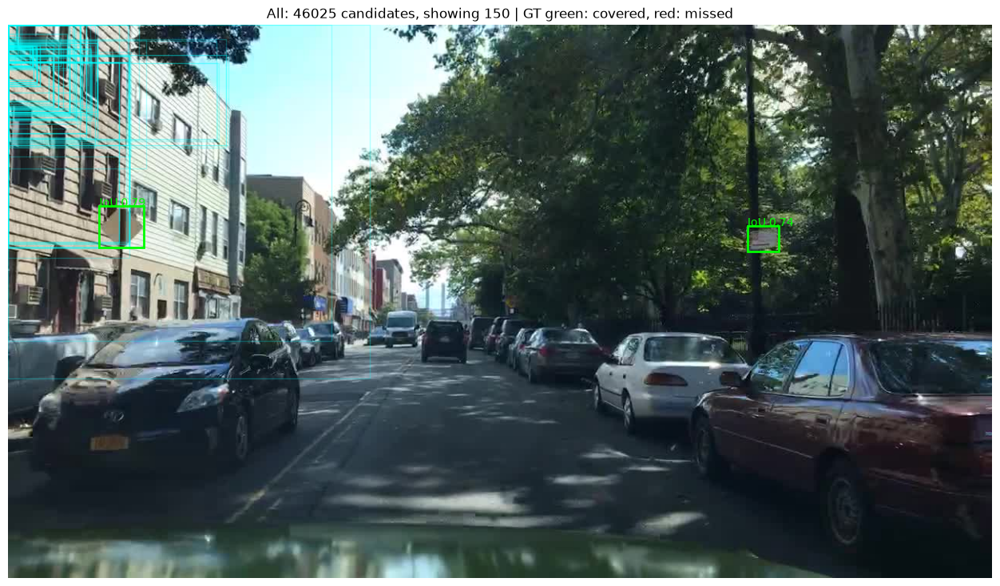

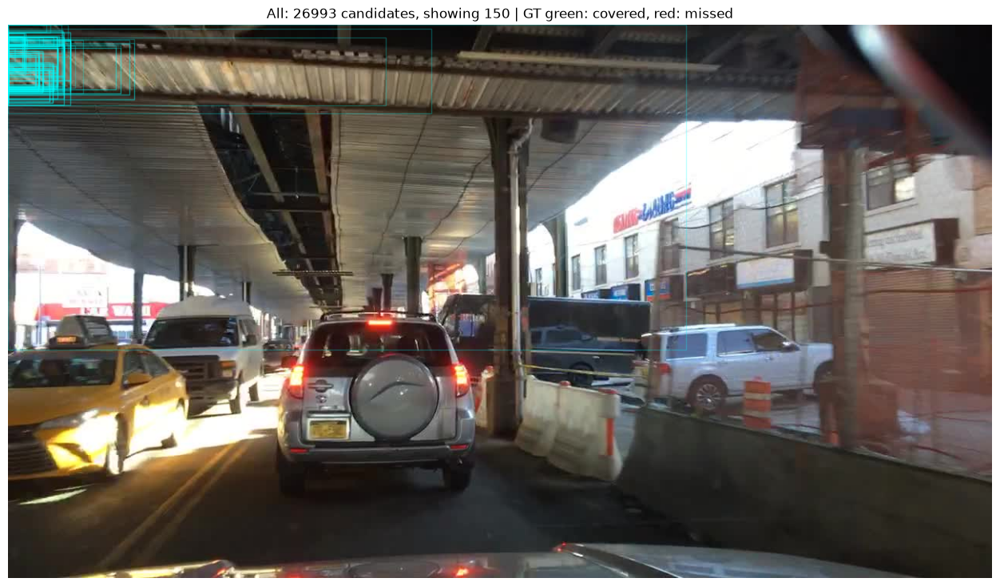

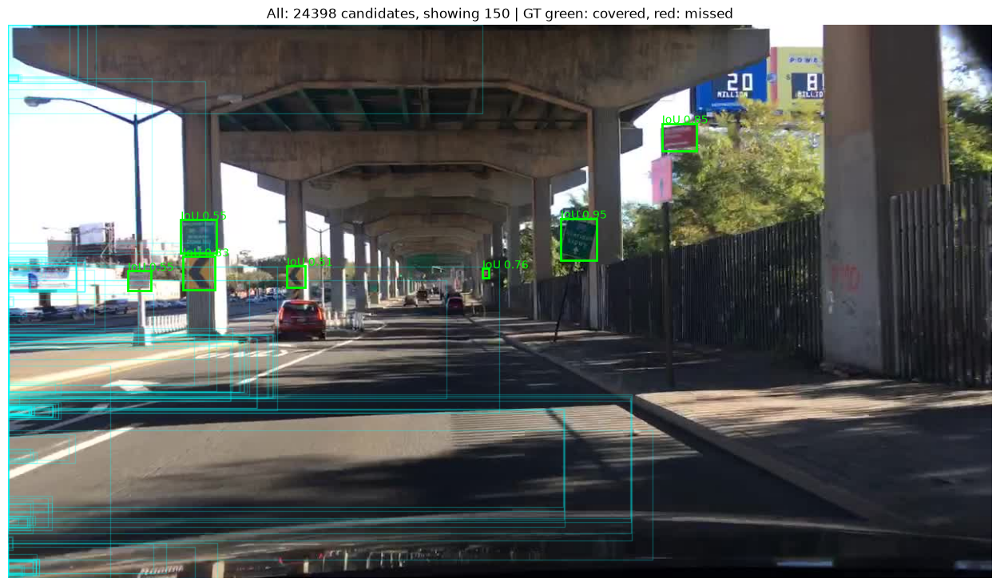

In [28]:
def show_candidates(path, method="All", maximum=150):
    image = read_image(path)
    truth = sign_boxes(path)
    boxes = candidate_cache[path.name][method]
    best = best_overlaps(truth, boxes)
    fig, ax = plt.subplots(figsize=(16, 9))
    ax.imshow(image)
    for box in boxes[:maximum]:
        x1, y1, x2, y2 = box
        ax.add_patch(Rectangle((x1, y1), x2-x1, y2-y1,
                               fill=False, edgecolor="cyan", alpha=0.25))
    for box, overlap in zip(truth, best):
        x1, y1, x2, y2 = box
        color = "lime" if overlap >= IOU_THRESHOLD else "red"
        ax.add_patch(Rectangle((x1, y1), x2-x1, y2-y1,
                               fill=False, edgecolor=color, linewidth=2))
        ax.text(x1, y1, f"IoU {overlap:.2f}", color=color)
    ax.set_title(f"{method}: {len(boxes)} candidates, showing {min(maximum, len(boxes))} | GT green: covered, red: missed")
    ax.axis("off")
    plt.show()


for path in sample_paths[:3]:
    show_candidates(path)

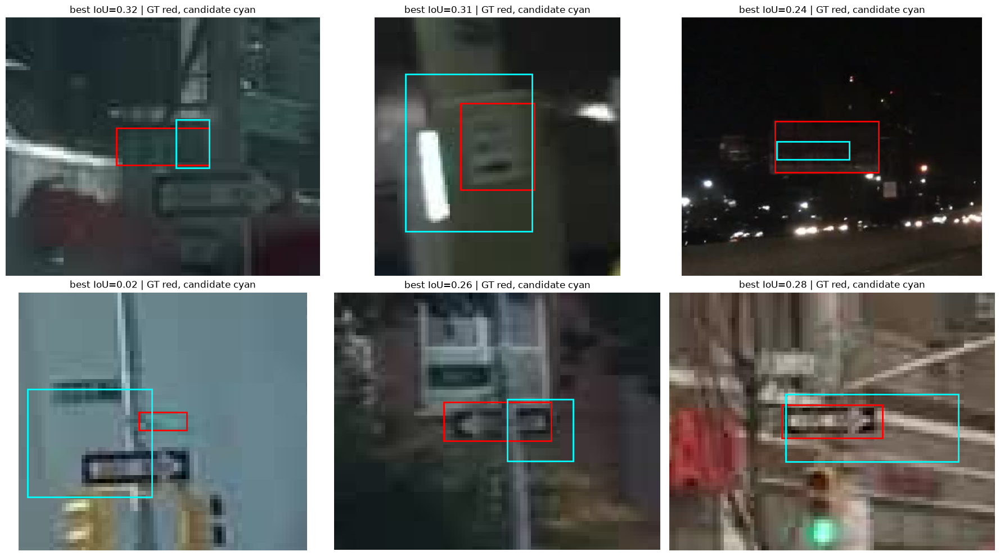

In [29]:
missed = details[(details["method"] == "All") & (details["best_iou"] < IOU_THRESHOLD)].head(6)
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
paths_by_name = {path.name: path for path in sample_paths}
for ax in axes.flat:
    ax.axis("off")
for ax, row in zip(axes.flat, missed.itertuples()):
    path = paths_by_name[row.image]
    image = read_image(path)
    truth = sign_boxes(path)[row.sign]
    candidates = candidate_cache[row.image]["All"]
    ax.imshow(image)
    x1, y1, x2, y2 = truth
    ax.add_patch(Rectangle((x1, y1), x2-x1, y2-y1, fill=False, edgecolor="red", linewidth=2))
    if len(candidates):
        box = candidates[np.argmax(iou(truth, candidates))]
        a, b, c, d = box
        ax.add_patch(Rectangle((a, b), c-a, d-b, fill=False, edgecolor="cyan", linewidth=2))
    margin = max(x2-x1, y2-y1, 30)
    ax.set_xlim(max(0, x1-margin), min(image.shape[1], x2+margin))
    ax.set_ylim(min(image.shape[0], y2+margin), max(0, y1-margin))
    ax.set_title(f"best IoU={row.best_iou:.2f} | GT red, candidate cyan")
plt.tight_layout()
plt.show()

In [30]:
RUN_VALIDATION = False
if RUN_VALIDATION:
    validation_paths = sorted(np.random.default_rng(123).choice(val_paths, size=100, replace=False))
    validation_summary, validation_records, validation_details, _ = measure_candidates(validation_paths)
    display(validation_summary)
    validation_summary.to_csv(OUTPUT_DIR / "validation_summary.csv")

Missed signs at IoU >= 0.33: 12
Showing 12 signs from 11 images


,image,sign,width,height,best_iou
396,1710645f-42a62094.jpg,2,25.312482,10.124995,0.322951
3564,7cddaf5e-38d398f7.jpg,2,32.062477,75.937448,0.324415
2719,50a95d7e-19a6f24c.jpg,2,17.468558,9.982034,0.270656
3869,875442bd-3a064de5.jpg,4,58.686845,20.173603,0.234656
5471,a1ce7bef-9019c338.jpg,2,23.963037,13.479208,0.319756
1793,416f06e2-0cf7289a.jpg,1,11.981510,4.493067,0.016567
2453,4e3d47e6-8b6acafa.jpg,6,26.850827,8.950276,0.275316
798,22998aac-eb4e419b.jpg,5,127.450152,62.957304,0.244020
2063,47e0d7e0-2766582e.jpg,9,29.383313,10.577993,0.259046
4076,8a1a1bb9-6f143006.jpg,2,32.062478,13.499991,0.329016


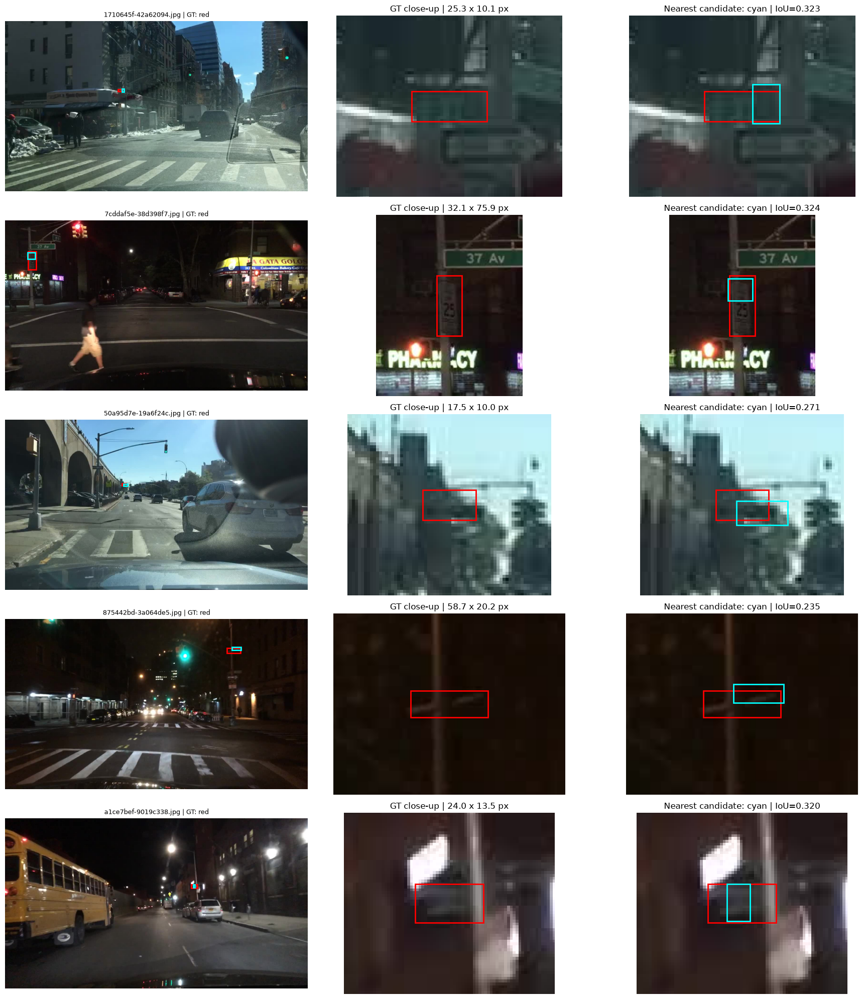

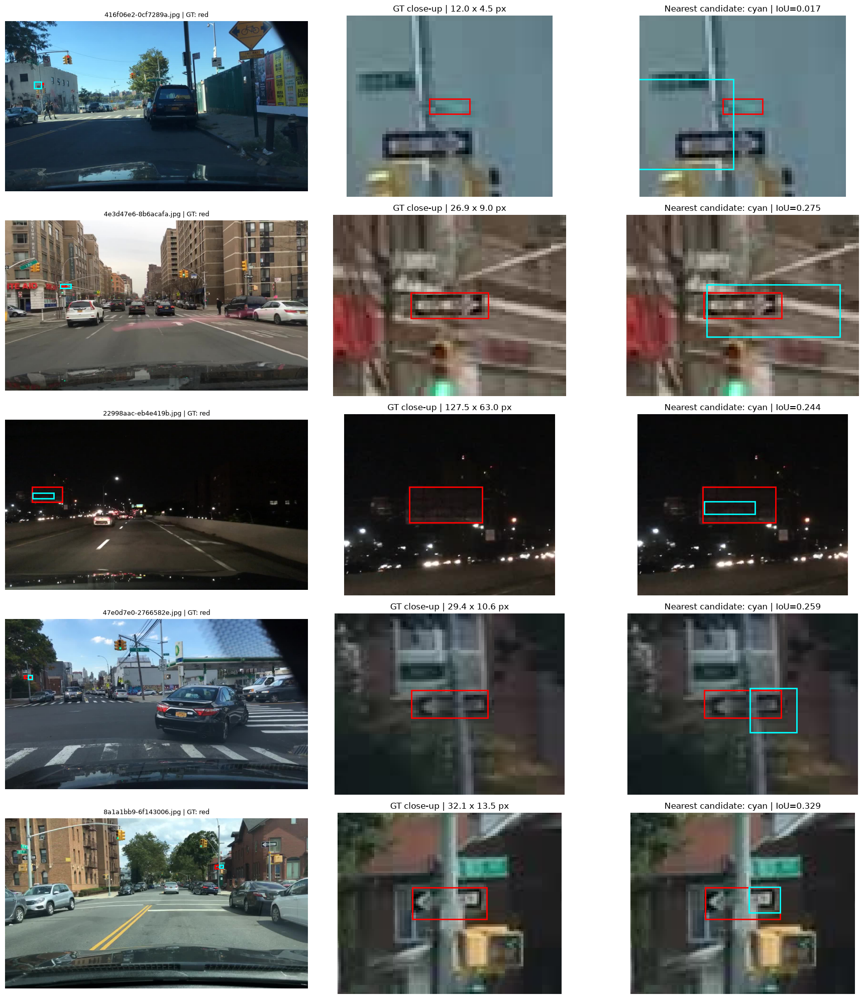

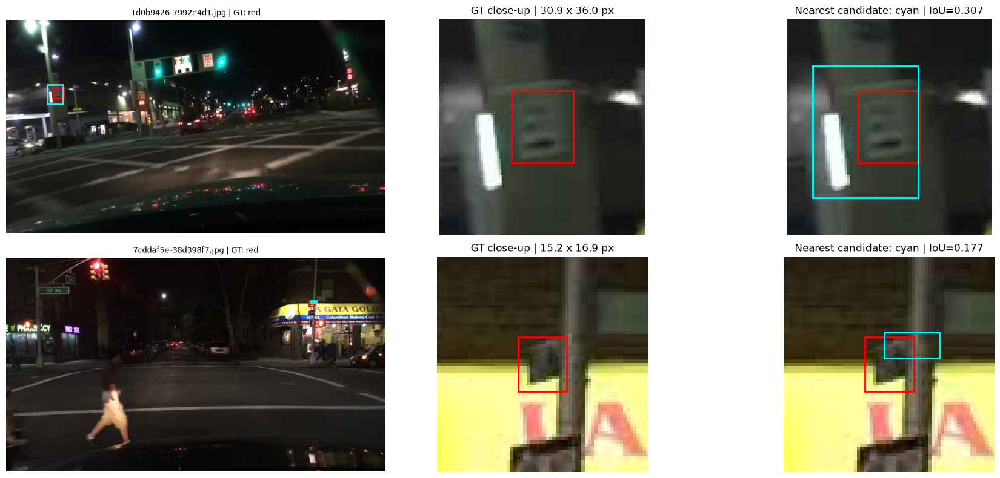

In [31]:
def review_missed_signs(review_paths, review_details, review_cache, max_signs=20, max_images=20):
    paths = {path.name: path for path in review_paths}
    missed = review_details[(review_details["method"] == "All") &
                            (review_details["best_iou"] < IOU_THRESHOLD)].copy()
    print(f"Missed signs at IoU >= {IOU_THRESHOLD}: {len(missed)}")
    rng = np.random.default_rng(42)
    selected = missed.iloc[rng.permutation(len(missed))]
    image_names = selected["image"].drop_duplicates().head(max_images)
    selected = selected[selected["image"].isin(image_names)].head(max_signs)
    print(f"Showing {len(selected)} signs from {selected['image'].nunique()} images")
    display(selected[["image", "sign", "width", "height", "best_iou"]])
    for start in range(0, len(selected), 5):
        page = selected.iloc[start:start+5]
        fig, axes = plt.subplots(len(page), 3, figsize=(18, 4 * len(page)), squeeze=False)
        for axes_row, row in zip(axes, page.itertuples()):
            path = paths[row.image]
            image = read_image(path)
            truth = sign_boxes(path)[row.sign]
            candidates = review_cache[row.image]["All"]
            nearest = candidates[np.argmax(iou(truth, candidates))] if len(candidates) else None
            x1, y1, x2, y2 = truth
            margin = max(x2-x1, y2-y1, 25)
            for ax in axes_row:
                ax.imshow(image)
                ax.add_patch(Rectangle((x1, y1), x2-x1, y2-y1,
                                       fill=False, edgecolor="red", linewidth=2))
                ax.axis("off")
            axes_row[0].set_title(f"{path.name} | GT: red", fontsize=9)
            if nearest is not None:
                a, b, c, d = nearest
                for ax in (axes_row[0], axes_row[2]):
                    ax.add_patch(Rectangle((a, b), c-a, d-b,
                                           fill=False, edgecolor="cyan", linewidth=2))
            for ax in axes_row[1:]:
                ax.set_xlim(max(0, x1-margin), min(image.shape[1], x2+margin))
                ax.set_ylim(min(image.shape[0], y2+margin), max(0, y1-margin))
            axes_row[1].set_title(f"GT close-up | {x2-x1:.1f} x {y2-y1:.1f} px")
            axes_row[2].set_title(f"Nearest candidate: cyan | IoU={row.best_iou:.3f}")
        plt.tight_layout()
        plt.show()


review_missed_signs(sample_paths, details, candidate_cache, max_signs=50)


In [32]:
test_paths = sorted((DATA_DIR / "photos/test").glob("*.jpg"))
test_review_paths = sorted(np.random.default_rng(42).choice(test_paths, size=10, replace=False))
test_review_summary, test_review_records, test_review_details, test_review_cache = measure_candidates(test_review_paths)
test_coverage = coverage_comparison(test_review_summary, test_review_details, IOU_THRESHOLD)
display(test_coverage)
review_missed_signs(test_review_paths, test_review_details, test_review_cache,
                    max_signs=20, max_images=10)


Candidates: 100%|██████████| 10/10 [00:10<00:00,  1.04s/it]


,Total signs,Covered,Missed,"Coverage, %",Candidates per image,Additional vs HSV+MSER,Additional vs original methods
method,,,,,,,
Adaptive,20,20,0,100.0,15095.7,12,8
All,20,20,0,100.0,23831.1,12,8
Original_Adaptive,20,20,0,100.0,16934.7,12,8
Original_CLAHE,20,16,4,80.0,4036.2,8,4
Original_Upscaled,20,15,5,75.0,3681.5,7,3
CLAHE,20,12,8,60.0,2442.3,4,0
Original_All,20,12,8,60.0,1851.9,4,0
Original_Grouped,20,12,8,60.0,4759.7,4,0
Baseline_Shapes,20,10,10,50.0,1411.5,2,-2


Missed signs at IoU >= 0.33: 0
Showing 0 signs from 0 images


,image,sign,width,height,best_iou


## Train model

In [33]:
from skimage.feature import hog
from sklearn.linear_model import SGDClassifier
from sklearn.metrics import classification_report
import joblib
import hashlib
import marshal

POSITIVE_IOU = 0.5
NEGATIVE_IOU = 0.2
TRAIN_EPOCHS = 2
NEGATIVES_PER_IMAGE = 60
TRAIN_IMAGE_LIMIT = None
TRAIN_OUTPUT = DATA_DIR.parent / "outputs/candidate_model"
TRAIN_OUTPUT.mkdir(parents=True, exist_ok=True)
functions = [rectangles_to_boxes, hsv_candidates, mser_candidates, shape_candidates,
             line_candidates, contrast_candidates, adaptive_candidates,
             grouped_candidates, upscaled_candidates, candidate_groups]
signature = hashlib.sha256(b"".join(marshal.dumps(f.__code__) for f in functions)
                           + repr((PADDING, MAX_LINES, POSITIVE_IOU, NEGATIVE_IOU,
                                   NEGATIVES_PER_IMAGE, "hog-hsv-v1")).encode()).hexdigest()[:12]
FEATURE_DIR = TRAIN_OUTPUT / f"features_{signature}"
FEATURE_DIR.mkdir(exist_ok=True)
training_paths = train_paths[:TRAIN_IMAGE_LIMIT]
training_rng = np.random.default_rng(42)

In [37]:
def candidate_features(image, box):
    height, width = image.shape[:2]
    x1, y1 = np.floor(box[:2]).astype(int)
    x2, y2 = np.ceil(box[2:]).astype(int)
    x1, y1 = np.clip(x1, 0, width-1), np.clip(y1, 0, height-1)
    x2, y2 = np.clip(x2, x1+1, width), np.clip(y2, y1+1, height)
    crop = cv2.resize(image[y1:y2, x1:x2], (64, 64))
    gray = cv2.cvtColor(crop, cv2.COLOR_RGB2GRAY)
    shape = hog(gray, orientations=9, pixels_per_cell=(8, 8),
                cells_per_block=(2, 2), block_norm="L2-Hys")
    hsv = cv2.cvtColor(crop, cv2.COLOR_RGB2HSV)
    color = np.concatenate([np.histogram(hsv[:, :, k], bins=16, range=(0, upper))[0]/4096
                            for k, upper in enumerate((180, 256, 256))])
    geometry = [np.log((x2-x1)/(y2-y1)), (x2-x1)/width, (y2-y1)/height]
    features = np.concatenate([shape, color, geometry]).astype(np.float32)
    return features / max(np.linalg.norm(features), 1e-9)


def candidate_labels(boxes, truth):
    overlaps = np.array([iou(box, truth).max(initial=0) for box in boxes])
    labels = np.full(len(boxes), -1, dtype=int)
    labels[overlaps < NEGATIVE_IOU] = 0
    labels[overlaps >= POSITIVE_IOU] = 1
    return labels


def training_candidates(path):
    image = read_image(path)
    boxes = candidate_groups(image)["All"]
    labels = candidate_labels(boxes, sign_boxes(path))
    positives = np.flatnonzero(labels == 1)
    negatives = np.flatnonzero(labels == 0)
    seed = int(hashlib.sha256(path.stem.encode()).hexdigest()[:8], 16)
    local_rng = np.random.default_rng(seed)
    negatives = local_rng.choice(negatives, min(NEGATIVES_PER_IMAGE, len(negatives)), replace=False)
    selected = np.r_[positives, negatives]
    features = np.asarray([candidate_features(image, boxes[i]) for i in selected],
                          dtype=np.float32).reshape(len(selected), 1815)
    return features, labels[selected]

In [40]:
import tempfile
import zipfile
import zlib
from joblib import Parallel, delayed, parallel_config

N_WORKERS = 6
print(f"Feature preparation workers: {N_WORKERS}")


def prepare_training_image(path):
    cv2.setNumThreads(1)
    feature_path = FEATURE_DIR / f"{path.stem}.npz"
    labels = None
    if feature_path.exists():
        try:
            with np.load(feature_path) as data:
                features, cached_labels = data["X"], data["y"]
                if (features.ndim == 2 and features.shape[1] == 1815
                        and cached_labels.ndim == 1 and len(features) == len(cached_labels)):
                    labels = cached_labels
        except (KeyError, ValueError, OSError, EOFError, zipfile.BadZipFile, zlib.error):
            pass
    if labels is None:
        features, labels = training_candidates(path)
        with tempfile.NamedTemporaryFile(dir=FEATURE_DIR, suffix=".tmp.npz", delete=False) as file:
            temporary_path = Path(file.name)
            np.savez_compressed(file, X=features, y=labels)
        temporary_path.replace(feature_path)
    return dict(image=path.name, positives=int((labels == 1).sum()),
                negatives=int((labels == 0).sum()))


with parallel_config(backend="loky", n_jobs=N_WORKERS, inner_max_num_threads=1):
    results = Parallel(return_as="generator_unordered", pre_dispatch=N_WORKERS, batch_size=1)(
        delayed(prepare_training_image)(path) for path in training_paths
    )
    training_counts = list(tqdm(results, total=len(training_paths),
                                desc=f"Training candidate features ({N_WORKERS} workers)"))
training_counts = pd.DataFrame(training_counts).sort_values("image").reset_index(drop=True)
print(f"Training images: {len(training_counts)}")
print(f"Positive candidate crops: {training_counts['positives'].sum()}")
print(f"Negative candidate crops: {training_counts['negatives'].sum()}")
print("Only generated candidate boxes are used. No ground-truth crops are added.")
training_counts.to_csv(TRAIN_OUTPUT / "training_counts.csv", index=False)


Feature preparation workers: 6


Training candidate features (6 workers):   4%|▍         | 2948/70000 [00:30<3:50:43,  4.84it/s]/Users/manoftheprincess/miniforge3/lib/python3.14/site-packages/joblib/externals/loky/process_executor.py:787: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(
Training candidate features (6 workers): 100%|██████████| 70000/70000 [3:55:31<00:00,  4.95it/s]  

Training images: 70000
Positive candidate crops: 2330350
Negative candidate crops: 4200000
Only generated candidate boxes are used. No ground-truth crops are added.


In [41]:
candidate_model = SGDClassifier(loss="hinge", alpha=0.0001, average=True, random_state=42)
for epoch in range(TRAIN_EPOCHS):
    batch_X, batch_y = [], []
    for index in tqdm(training_rng.permutation(len(training_paths)), desc=f"SVM epoch {epoch+1}"):
        path = training_paths[index]
        with np.load(FEATURE_DIR / f"{path.stem}.npz") as data:
            batch_X.extend(data["X"])
            batch_y.extend(data["y"])
        if len(batch_y) >= 4096:
            X, y = np.asarray(batch_X, dtype=np.float32), np.asarray(batch_y)
            counts = np.bincount(y, minlength=2)
            weights = (len(y)/(2*np.maximum(counts[y], 1))).astype(np.float32)
            candidate_model.partial_fit(X, y, classes=[0, 1], sample_weight=weights)
            batch_X, batch_y = [], []
    if len(batch_y):
        X, y = np.asarray(batch_X, dtype=np.float32), np.asarray(batch_y)
        counts = np.bincount(y, minlength=2)
        weights = (len(y)/(2*np.maximum(counts[y], 1))).astype(np.float32)
        candidate_model.partial_fit(X, y, classes=[0, 1], sample_weight=weights)
joblib.dump(dict(model=candidate_model, positive_iou=POSITIVE_IOU,
                 negative_iou=NEGATIVE_IOU, feature_signature=signature),
            TRAIN_OUTPUT / "candidate_svm.joblib")

SVM epoch 2: 100%|██████████| 70000/70000 [03:20<00:00, 349.58it/s]


['outputs/candidate_model/candidate_svm.joblib']

In [42]:
def score_candidates(path):
    image = read_image(path)
    boxes = candidate_groups(image)["All"]
    scores = np.empty(len(boxes))
    for start in range(0, len(boxes), 512):
        features = np.asarray([candidate_features(image, box) for box in boxes[start:start+512]])
        scores[start:start+512] = candidate_model.decision_function(features)
    return boxes, scores


def candidate_nms(boxes, scores, threshold=0.4):
    order = np.argsort(scores)[::-1]
    keep = []
    while len(order):
        index = order[0]
        keep.append(index)
        rest = order[1:]
        order = rest[iou(boxes[index], boxes[rest]) <= threshold]
    return np.asarray(keep, dtype=int)


model_val_paths = sorted(np.random.default_rng(123).choice(val_paths, size=50, replace=False))
model_val_predictions = {}
validation_y, validation_scores = [], []
for path in tqdm(model_val_paths, desc="Validation candidates"):
    boxes, scores = score_candidates(path)
    labels = candidate_labels(boxes, sign_boxes(path))
    selected = labels >= 0
    validation_y.extend(labels[selected])
    validation_scores.extend(scores[selected])
    model_val_predictions[path.name] = dict(boxes=boxes.tolist(), scores=scores.tolist())
print(classification_report(validation_y, np.asarray(validation_scores) >= 0,
                            target_names=["background", "traffic_sign"], labels=[0, 1],
                            zero_division=0))

Validation candidates: 100%|██████████| 50/50 [09:36<00:00, 11.54s/it]


              precision    recall  f1-score   support

  background       1.00      0.82      0.90   1153092
traffic_sign       0.01      0.92      0.01      1223

    accuracy                           0.82   1154315
   macro avg       0.50      0.87      0.46   1154315
weighted avg       1.00      0.82      0.90   1154315



In [43]:
def detection_metrics(paths, predictions, score_threshold, overlap_threshold=0.5):
    tp, fp, fn = 0, 0, 0
    for path in paths:
        truth = sign_boxes(path)
        result = predictions[path.name]
        boxes = np.asarray(result["boxes"]).reshape(-1, 4)
        scores = np.asarray(result["scores"])
        selected = scores >= score_threshold
        boxes, scores = boxes[selected], scores[selected]
        boxes = boxes[candidate_nms(boxes, scores)]
        used = set()
        for box in boxes:
            overlaps = iou(box, truth)
            available = [i for i in range(len(truth)) if i not in used]
            best = max(available, key=lambda i: overlaps[i], default=-1)
            if best >= 0 and overlaps[best] >= overlap_threshold:
                tp += 1
                used.add(best)
            else:
                fp += 1
        fn += len(truth)-len(used)
    precision = tp/max(tp+fp, 1)
    recall = tp/max(tp+fn, 1)
    return dict(precision=precision, recall=recall,
                F1=2*precision*recall/max(precision+recall, 1e-9), TP=tp, FP=fp, FN=fn)


threshold_results = pd.DataFrame([
    dict(threshold=threshold, **detection_metrics(model_val_paths, model_val_predictions, threshold))
    for threshold in [-2, -1, -0.5, 0, 0.5, 1, 2]
]).sort_values("F1", ascending=False)
display(threshold_results)
model_score_threshold = float(threshold_results.iloc[0]["threshold"])
threshold_results.to_csv(TRAIN_OUTPUT / "validation_detection.csv", index=False)
(TRAIN_OUTPUT / "validation_predictions.json").write_text(json.dumps(model_val_predictions))

,threshold,precision,recall,F1,TP,FP,FN
6,2.0,0.041498,0.362832,0.074478,41,947,72
5,1.0,0.008912,0.619469,0.017570,70,7785,43
4,0.5,0.004279,0.707965,0.008506,80,18618,33
3,0.0,0.002259,0.752212,0.004505,85,37536,28
2,-0.5,0.001387,0.787611,0.002770,89,64063,24
1,-1.0,0.000910,0.796460,0.001817,90,98851,23
0,-2.0,0.000476,0.796460,0.000952,90,188955,23


58586429

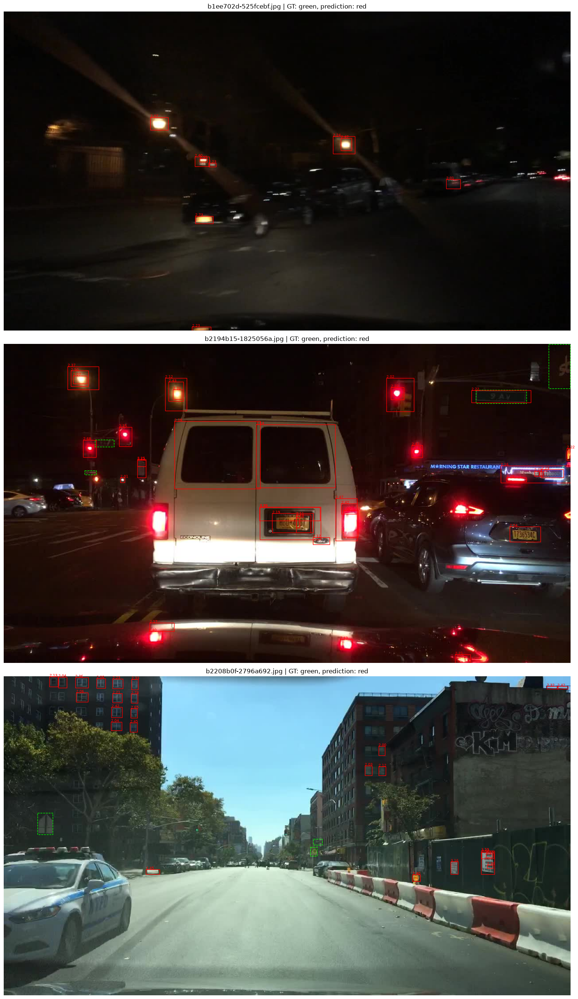

In [44]:
fig, axes = plt.subplots(3, 1, figsize=(16, 27))
for ax, path in zip(axes, model_val_paths[:3]):
    ax.imshow(read_image(path))
    for box in sign_boxes(path):
        x1, y1, x2, y2 = box
        ax.add_patch(Rectangle((x1, y1), x2-x1, y2-y1,
                               fill=False, edgecolor="lime", linestyle="--"))
    result = model_val_predictions[path.name]
    boxes = np.asarray(result["boxes"]).reshape(-1, 4)
    scores = np.asarray(result["scores"])
    selected = scores >= model_score_threshold
    boxes, scores = boxes[selected], scores[selected]
    keep = candidate_nms(boxes, scores)
    for box, score in zip(boxes[keep], scores[keep]):
        x1, y1, x2, y2 = box
        ax.add_patch(Rectangle((x1, y1), x2-x1, y2-y1,
                               fill=False, edgecolor="red"))
        ax.text(x1, y1, f"{score:.2f}", color="red", fontsize=7)
    ax.set_title(f"{path.name} | GT: green, prediction: red")
    ax.axis("off")
plt.tight_layout()
plt.show()

## Two-stage held-out evaluation


In [45]:
EVAL_SPLIT = "test"
EVAL_IMAGES = 200
EVAL_IOU = 0.5
EVAL_SCORE_THRESHOLD = model_score_threshold
ERRORS_PER_TYPE = 20
all_eval_paths = sorted((DATA_DIR / "photos" / EVAL_SPLIT).glob("*.jpg"))
eval_paths = sorted(np.random.default_rng(2026).choice(all_eval_paths, EVAL_IMAGES, replace=False))
EVAL_OUTPUT = TRAIN_OUTPUT / f"staged_{EVAL_SPLIT}_{signature}"
EVAL_OUTPUT.mkdir(parents=True, exist_ok=True)

In [46]:
proposal_rows, eval_sign_rows = [], []
for path in tqdm(eval_paths, desc="Stage 1: candidate coverage"):
    cache_path = EVAL_OUTPUT / f"{path.stem}_boxes.npy"
    if cache_path.exists():
        boxes = np.load(cache_path)
    else:
        boxes = candidate_groups(read_image(path))["All"]
        np.save(cache_path, boxes)
    truth = sign_boxes(path)
    best = best_overlaps(truth, boxes)
    matched_candidates = sum(np.any(iou(box, truth) >= EVAL_IOU) for box in boxes)
    proposal_rows.append(dict(image=path.name, signs=len(truth), boxes=len(boxes),
                              covered=int((best >= EVAL_IOU).sum()),
                              matching_boxes=int(matched_candidates)))
    for index, (box, overlap) in enumerate(zip(truth, best)):
        eval_sign_rows.append(dict(image=path.name, sign=index, candidate_iou=overlap,
                                  width=box[2]-box[0], height=box[3]-box[1]))
proposal_results = pd.DataFrame(proposal_rows)
eval_signs = pd.DataFrame(eval_sign_rows)
total_signs = int(proposal_results["signs"].sum())
covered_signs = int(proposal_results["covered"].sum())
print(f"Split: {EVAL_SPLIT}; images: {len(eval_paths)}; IoU threshold: {EVAL_IOU}")
print(f"Generated boxes: {proposal_results['boxes'].sum()}")
print(f"Boxes matching a ground-truth sign: {proposal_results['matching_boxes'].sum()}")
print(f"Images containing signs: {(proposal_results['signs'] > 0).sum()}")
print(f"Images with at least one covered sign: {(proposal_results['covered'] > 0).sum()}")
print(f"Ground-truth signs covered: {covered_signs}/{total_signs} ({100*covered_signs/max(total_signs,1):.2f}%)")
print(f"Ground-truth signs missed by generator: {total_signs-covered_signs}")
proposal_results.to_csv(EVAL_OUTPUT / "candidate_coverage.csv", index=False)
eval_signs.to_csv(EVAL_OUTPUT / "sign_coverage.csv", index=False)

Stage 1: candidate coverage: 100%|██████████| 200/200 [02:03<00:00,  1.62it/s]

Split: test; images: 200; IoU threshold: 0.5
Generated boxes: 4921646
Boxes matching a ground-truth sign: 6435
Images containing signs: 166
Images with at least one covered sign: 157
Ground-truth signs covered: 539/636 (84.75%)
Ground-truth signs missed by generator: 97


In [47]:
model_digest = hashlib.sha256(candidate_model.coef_.tobytes() + candidate_model.intercept_.tobytes()).hexdigest()[:12]
eval_predictions = {}
candidate_truth, candidate_decisions = [], []
for path in tqdm(eval_paths, desc="Stage 2: classify cached candidates"):
    boxes = np.load(EVAL_OUTPUT / f"{path.stem}_boxes.npy")
    scores_path = EVAL_OUTPUT / f"{path.stem}_{model_digest}_scores.npy"
    if scores_path.exists():
        scores = np.load(scores_path)
    else:
        image = read_image(path)
        scores = np.empty(len(boxes))
        for start in range(0, len(boxes), 512):
            features = np.asarray([candidate_features(image, box) for box in boxes[start:start+512]])
            scores[start:start+512] = candidate_model.decision_function(features)
        np.save(scores_path, scores)
    labels = candidate_labels(boxes, sign_boxes(path))
    eligible = labels >= 0
    candidate_truth.extend(labels[eligible])
    candidate_decisions.extend(scores[eligible] >= EVAL_SCORE_THRESHOLD)
    selected = scores >= EVAL_SCORE_THRESHOLD
    filtered_boxes, filtered_scores = boxes[selected], scores[selected]
    keep = candidate_nms(filtered_boxes, filtered_scores)
    eval_predictions[path.name] = dict(boxes=filtered_boxes[keep].tolist(),
                                       scores=filtered_scores[keep].tolist())
print(f"Fixed classifier threshold from validation: {EVAL_SCORE_THRESHOLD}")
print(classification_report(candidate_truth, candidate_decisions, labels=[0,1],
                            target_names=["background", "traffic_sign"], zero_division=0))
final_metrics = detection_metrics(eval_paths, eval_predictions, EVAL_SCORE_THRESHOLD, EVAL_IOU)
staged_metrics = pd.DataFrame([dict(
    split=EVAL_SPLIT, images=len(eval_paths), IoU=EVAL_IOU,
    ground_truth_signs=total_signs, candidate_covered_signs=covered_signs,
    candidate_recall=covered_signs/max(total_signs,1),
    covered_signs_retained=final_metrics["TP"]/max(covered_signs,1), **final_metrics)])
display(staged_metrics)
staged_metrics.to_csv(EVAL_OUTPUT / "stage_metrics.csv", index=False)
(EVAL_OUTPUT / "predictions.json").write_text(json.dumps(eval_predictions))

Stage 2: classify cached candidates: 100%|██████████| 200/200 [39:06<00:00, 11.73s/it]


Fixed classifier threshold from validation: 2.0
              precision    recall  f1-score   support

  background       1.00      1.00      1.00   4899225
traffic_sign       0.08      0.25      0.12      6435

    accuracy                           0.99   4905660
   macro avg       0.54      0.62      0.56   4905660
weighted avg       1.00      0.99      1.00   4905660



,split,images,IoU,ground_truth_signs,candidate_covered_signs,candidate_recall,covered_signs_retained,precision,recall,F1,TP,FP,FN
0,test,200,0.5,636,539,0.847484,0.363636,0.045497,0.308176,0.079288,196,4112,440


223137

error
classifier_or_NMS_miss     343
false_positive            4112
generator_miss              97
Name: count, dtype: int64

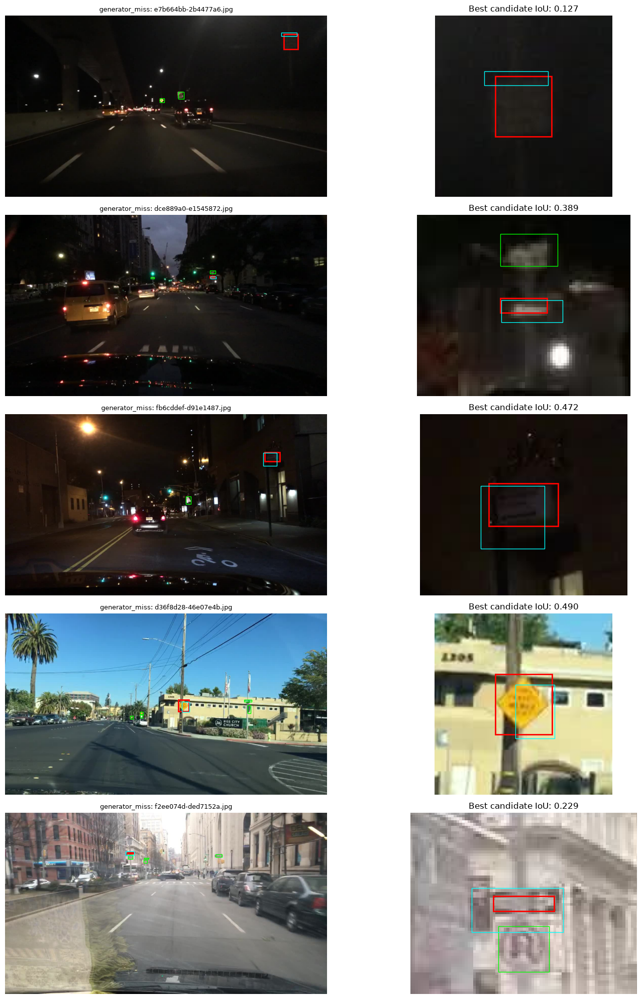

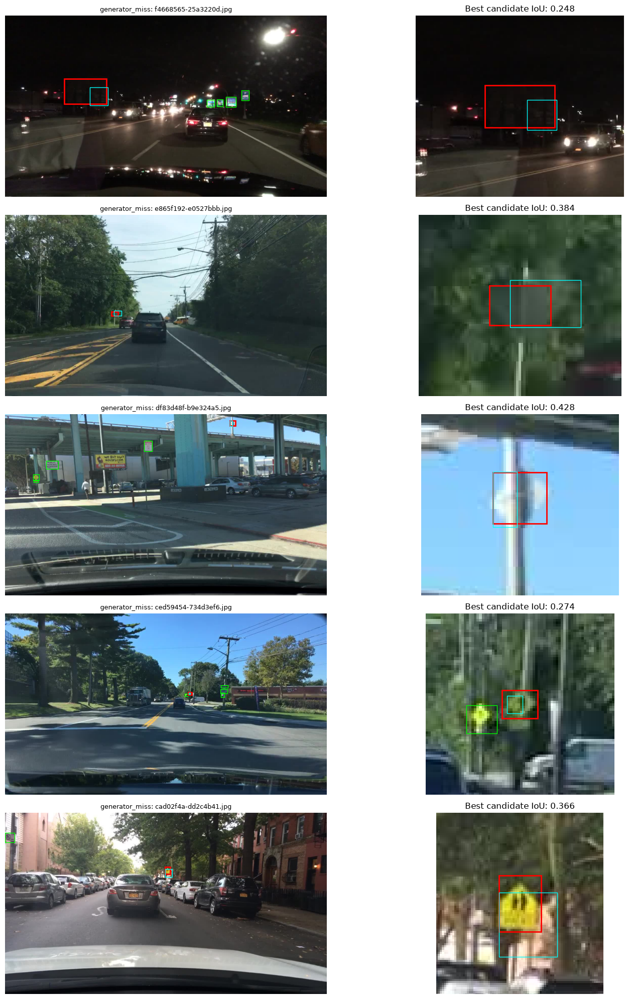

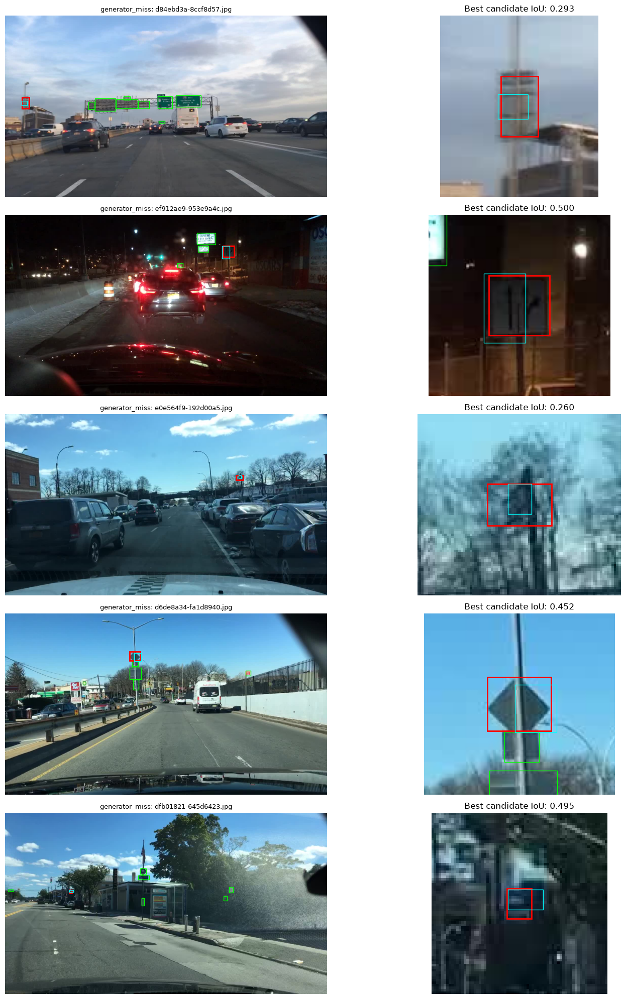

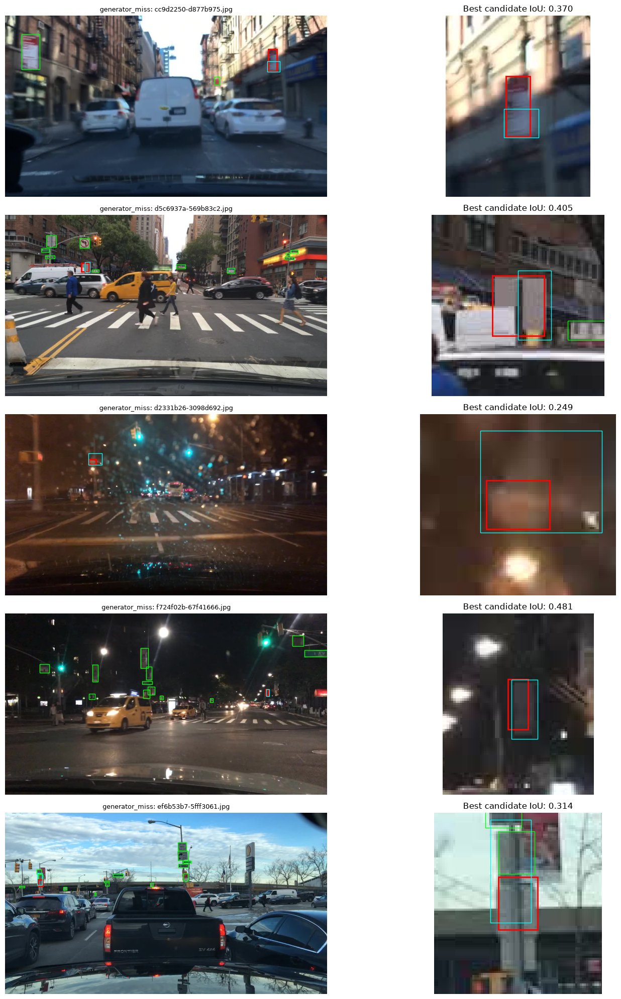

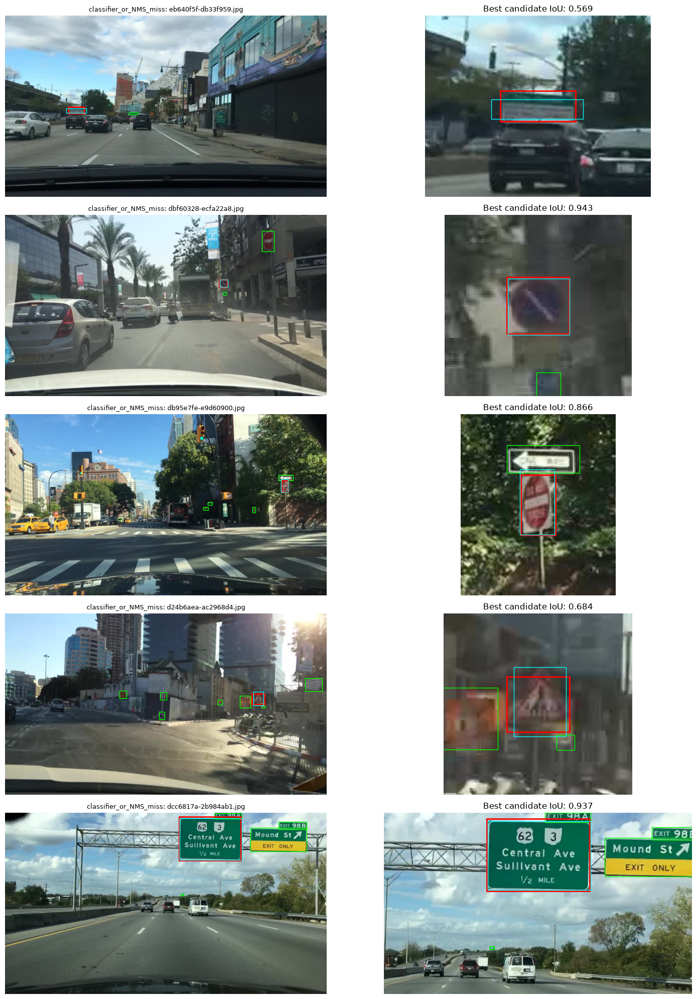

...

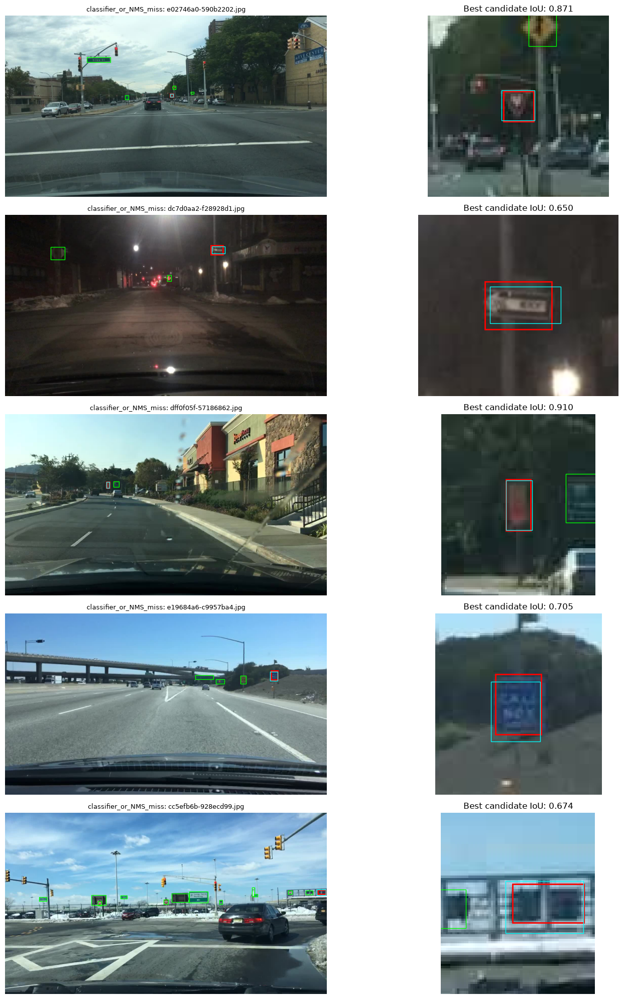

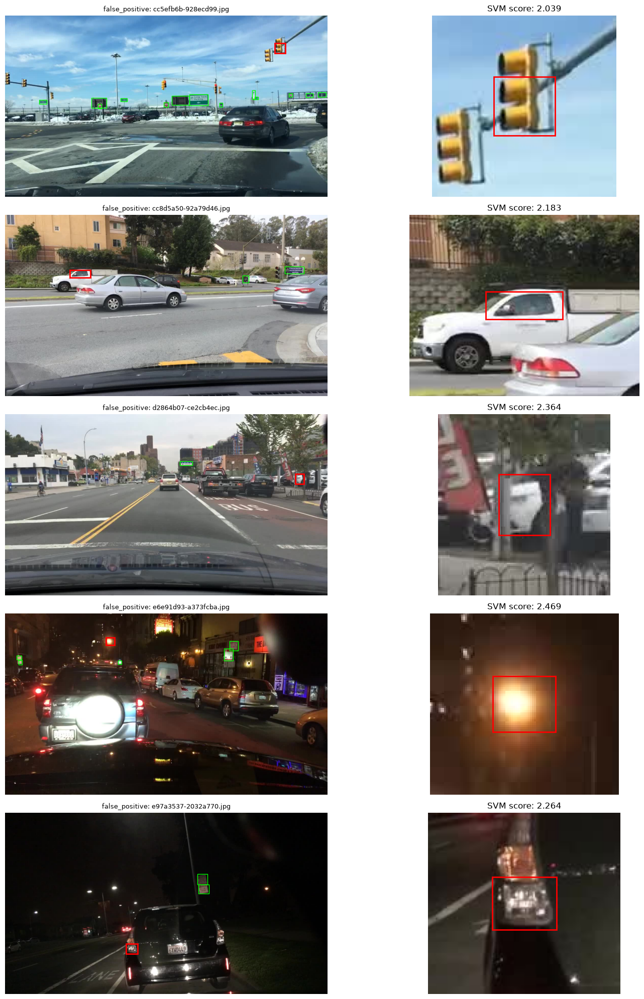

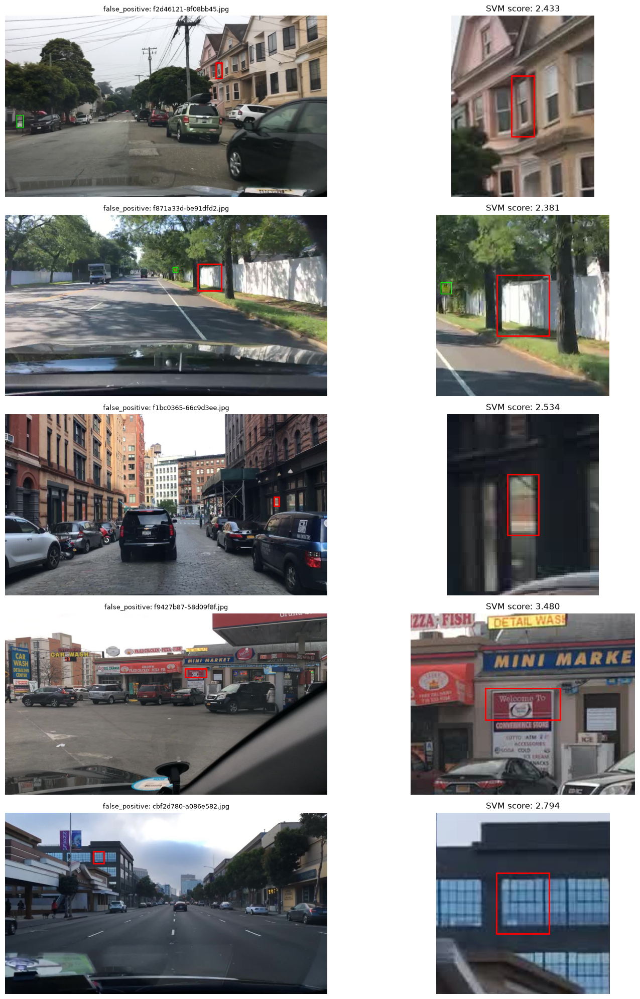

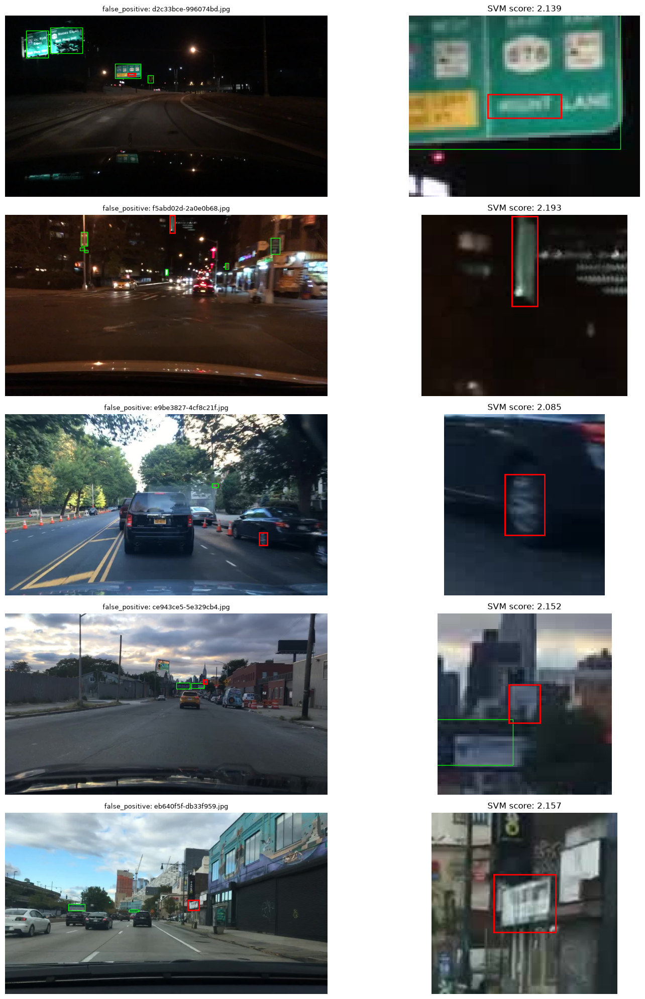

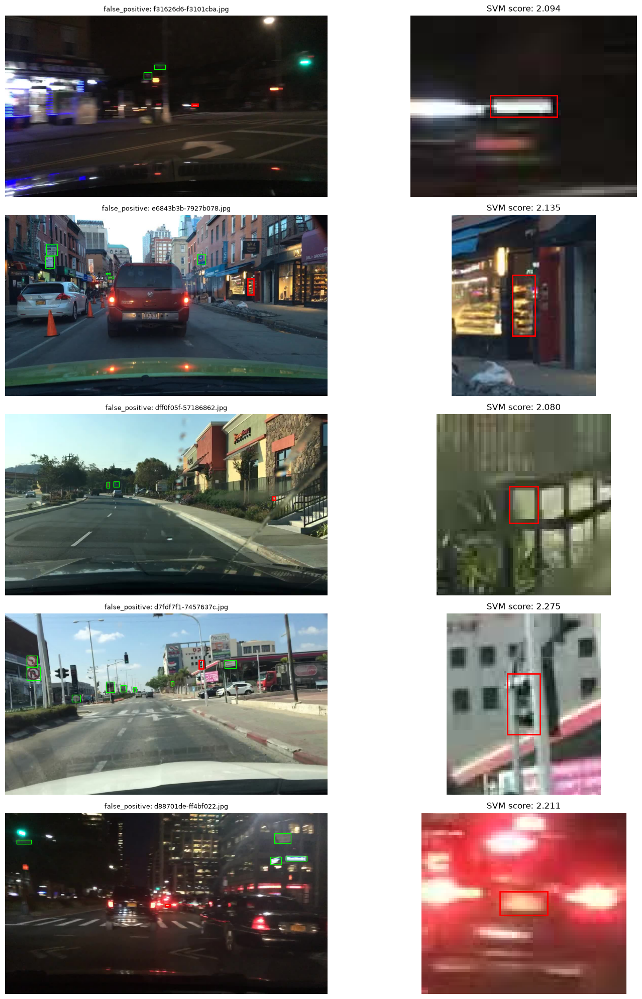

In [48]:
error_rows = []
paths_by_name = {path.name: path for path in eval_paths}
for path in eval_paths:
    truth = sign_boxes(path)
    proposals = np.load(EVAL_OUTPUT / f"{path.stem}_boxes.npy")
    best = best_overlaps(truth, proposals)
    result = eval_predictions[path.name]
    boxes = np.asarray(result["boxes"]).reshape(-1,4)
    used = set()
    for box, score in zip(boxes, result["scores"]):
        overlaps = iou(box, truth)
        available = [i for i in range(len(truth)) if i not in used]
        index = max(available, key=lambda i: overlaps[i], default=-1)
        if index >= 0 and overlaps[index] >= EVAL_IOU:
            used.add(index)
        else:
            error_rows.append(dict(image=path.name, error="false_positive", sign=-1,
                                   x1=box[0], y1=box[1], x2=box[2], y2=box[3],
                                   value=score))
    for index, box in enumerate(truth):
        if index not in used:
            kind = "generator_miss" if best[index] < EVAL_IOU else "classifier_or_NMS_miss"
            error_rows.append(dict(image=path.name, error=kind, sign=index,
                                   x1=box[0], y1=box[1], x2=box[2], y2=box[3],
                                   value=best[index]))
eval_errors = pd.DataFrame(error_rows, columns=["image","error","sign","x1","y1","x2","y2","value"])
eval_errors.to_csv(EVAL_OUTPUT / "errors.csv", index=False)
display(eval_errors.groupby("error").size().rename("count"))
for kind in ("generator_miss", "classifier_or_NMS_miss", "false_positive"):
    examples = eval_errors[eval_errors["error"] == kind].sample(frac=1, random_state=42).head(ERRORS_PER_TYPE)
    for start in range(0, len(examples), 5):
        page = examples.iloc[start:start+5]
        fig, axes = plt.subplots(len(page), 2, figsize=(16, 4*len(page)), squeeze=False)
        for axes_row, row in zip(axes, page.itertuples()):
            path = paths_by_name[row.image]
            image = read_image(path)
            box = np.array([row.x1,row.y1,row.x2,row.y2])
            nearest = None
            if kind != "false_positive":
                proposals = np.load(EVAL_OUTPUT / f"{path.stem}_boxes.npy")
                if len(proposals):
                    nearest = proposals[np.argmax(iou(box,proposals))]
            for ax in axes_row:
                ax.imshow(image)
                for gt in sign_boxes(path):
                    x1,y1,x2,y2 = gt
                    ax.add_patch(Rectangle((x1,y1),x2-x1,y2-y1,fill=False,edgecolor="lime",linewidth=1))
                ax.add_patch(Rectangle((row.x1,row.y1),row.x2-row.x1,row.y2-row.y1,
                                       fill=False,edgecolor="red",linewidth=2))
                if nearest is not None:
                    x1,y1,x2,y2=nearest
                    ax.add_patch(Rectangle((x1,y1),x2-x1,y2-y1,fill=False,edgecolor="cyan"))
                ax.axis("off")
            margin=max(row.x2-row.x1,row.y2-row.y1,30)
            axes_row[1].set_xlim(max(0,row.x1-margin),min(image.shape[1],row.x2+margin))
            axes_row[1].set_ylim(min(image.shape[0],row.y2+margin),max(0,row.y1-margin))
            axes_row[0].set_title(f"{kind}: {row.image}",fontsize=9)
            axes_row[1].set_title(f"{'SVM score' if kind == 'false_positive' else 'Best candidate IoU'}: {row.value:.3f}")
        plt.tight_layout()
        plt.show()

## Feature importance and boosting


In [2]:
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import average_precision_score
from skimage.feature import graycomatrix, graycoprops, local_binary_pattern
from threadpoolctl import threadpool_limits

BOOST_OUTPUT = TRAIN_OUTPUT / "boosting"
BOOST_OUTPUT.mkdir(exist_ok=True)
feature_names = []
for block_y in range(7):
    for block_x in range(7):
        for cell_y in range(2):
            for cell_x in range(2):
                for orientation in range(9):
                    feature_names.append(f"hog_b{block_y}_{block_x}_c{cell_y}_{cell_x}_o{orientation}")
feature_names += [f"hsv_{channel}_{index}" for channel in "HSV" for index in range(16)]
feature_names += ["log_aspect_ratio", "relative_width", "relative_height"]
feature_groups = {"HOG": np.arange(1764), "HSV": np.arange(1764,1812),
                  "Geometry": np.arange(1812,1815)}
feature_rng = np.random.default_rng(2026)
importance_paths = sorted(feature_rng.choice(val_paths, size=20, replace=False))
remaining_val = [path for path in val_paths if path not in set(importance_paths)]
boost_tuning_paths = sorted(feature_rng.choice(remaining_val, size=25, replace=False))
remaining_val = [path for path in remaining_val if path not in set(boost_tuning_paths)]
boost_assessment_paths = sorted(feature_rng.choice(remaining_val, size=50, replace=False))

NameError: name 'TRAIN_OUTPUT' is not defined

In [55]:
importance_X, importance_y = [], []
for path in tqdm(importance_paths, desc="Feature importance validation sample"):
    image = read_image(path)
    boxes = candidate_groups(image)["All"]
    labels = candidate_labels(boxes, sign_boxes(path))
    positive = np.flatnonzero(labels == 1)
    negative = np.flatnonzero(labels == 0)
    selected = np.r_[feature_rng.choice(positive, min(30,len(positive)), replace=False),
                     feature_rng.choice(negative, min(200,len(negative)), replace=False)]
    importance_X.extend(candidate_features(image,boxes[i]) for i in selected)
    importance_y.extend(labels[selected])
importance_X = np.asarray(importance_X,dtype=np.float32)
importance_y = np.asarray(importance_y)
importance_scores = candidate_model.decision_function(importance_X)
base_ap = average_precision_score(importance_y,importance_scores)
weights = candidate_model.coef_[0]
feature_ranking = pd.DataFrame(dict(
    index=np.arange(1815), feature=feature_names, coefficient=weights,
    mean_abs_contribution=np.mean(np.abs(importance_X * weights),axis=0)))
feature_ranking = feature_ranking.sort_values("mean_abs_contribution",ascending=False)
group_rows = []
for name, indices in feature_groups.items():
    drops = []
    for repeat in range(5):
        shuffled = importance_X.copy()
        permutation = feature_rng.permutation(len(shuffled))
        shuffled[:,indices] = importance_X[permutation][:,indices]
        drops.append(base_ap-average_precision_score(importance_y,candidate_model.decision_function(shuffled)))
    group_rows.append(dict(group=name, features=len(indices), AP_drop=np.mean(drops),
                           AP_drop_std=np.std(drops)))
group_importance = pd.DataFrame(group_rows).sort_values("AP_drop",ascending=False)
print(f"Baseline average precision on sampled validation candidates: {base_ap:.4f}")
display(group_importance)
display(feature_ranking.head(30))
group_importance.to_csv(BOOST_OUTPUT / "group_importance.csv",index=False)

Feature importance validation sample: 100%|██████████| 20/20 [00:13<00:00,  1.43it/s]


Baseline average precision on sampled validation candidates: 0.5890


,group,features,AP_drop,AP_drop_std
0,HOG,1764,0.517155,0.005318
1,HSV,48,0.028119,0.006621
2,Geometry,3,-0.000828,0.003166


,index,feature,coefficient,mean_abs_contribution
1812,1812,log_aspect_ratio,-1.386559,0.107582
1782,1782,hsv_S_2,-3.423338,0.067716
1741,1741,hog_b6_6_c0_1_o4,-1.877705,0.067420
256,256,hog_b1_0_c0_0_o4,-2.015243,0.067351
481,481,hog_b1_6_c0_1_o4,-1.969608,0.065967
1516,1516,hog_b6_0_c0_0_o4,-1.862571,0.065812
1507,1507,hog_b5_6_c1_1_o4,-1.874301,0.063853
1282,1282,hog_b5_0_c1_0_o4,-1.823317,0.061428
1781,1781,hsv_S_1,-3.139205,0.059872
22,22,hog_b0_0_c1_0_o4,-1.640691,0.057973


In [56]:
permutation_rows = []
for index in tqdm(feature_ranking.head(128)["index"],desc="Individual feature importance"):
    drops = []
    for repeat in range(3):
        shuffled = importance_X.copy()
        shuffled[:,index] = shuffled[feature_rng.permutation(len(shuffled)),index]
        drops.append(base_ap-average_precision_score(importance_y,candidate_model.decision_function(shuffled)))
    permutation_rows.append(dict(index=index, AP_drop=np.mean(drops)))
individual_importance = pd.DataFrame(permutation_rows).sort_values("AP_drop",ascending=False)
feature_ranking = feature_ranking.merge(individual_importance,on="index",how="left")
feature_ranking.to_csv(BOOST_OUTPUT / "feature_importance.csv",index=False)
selected_indices = np.unique(np.r_[individual_importance.head(64)["index"].to_numpy(dtype=int),
                                    feature_ranking.sort_values("mean_abs_contribution",ascending=False).head(128)["index"].to_numpy(dtype=int),
                                    np.arange(1764,1815)])
print(f"Selected features for boosting: {len(selected_indices)}")
display(feature_ranking.sort_values("AP_drop",ascending=False).head(30))

Individual feature importance: 100%|██████████| 128/128 [00:01<00:00, 76.18it/s]

Selected features for boosting: 164


,index,feature,coefficient,mean_abs_contribution,AP_drop
17,1780,hsv_S_0,-3.287346,0.055756,0.020820
8,1781,hsv_S_1,-3.139205,0.059872,0.007811
117,1770,hsv_H_6,1.761893,0.009108,0.004728
39,1773,hsv_H_9,-2.466312,0.030988,0.003382
28,36,hog_b0_1_c0_0_o0,-1.597638,0.050050,0.003375
1,1782,hsv_S_2,-3.423338,0.067716,0.003022
9,22,hog_b0_0_c1_0_o4,-1.640691,0.057973,0.002801
41,1759,hog_b6_6_c1_1_o4,-1.055271,0.030244,0.002510
59,1771,hsv_H_7,2.375620,0.015822,0.002504
37,229,hog_b0_6_c0_1_o4,-1.160818,0.032615,0.002192


In [1]:
balance_rng = np.random.default_rng(2026)
cache_paths = sorted(path for path in FEATURE_DIR.glob("*.npz")
                     if not path.name.endswith(".tmp.npz"))
class_counts = np.zeros(2,dtype=np.int64)
cache_count_rows = []
for path in tqdm(cache_paths,desc="Count all cached training labels"):
    with np.load(path) as data:
        counts = np.bincount(data["y"].astype(int),minlength=2)
    class_counts += counts
    cache_count_rows.append(dict(file=path.name,background=int(counts[0]),traffic_sign=int(counts[1])))
display(pd.DataFrame({"class":["background","traffic_sign"],"original_count":class_counts}))
pd.DataFrame(cache_count_rows).to_csv(BOOST_OUTPUT / "all_training_class_counts.csv",index=False)


AUGMENT_HORIZONTAL_FLIP = False


def augment_candidate_pixels(image,box,rng):
    height,width=image.shape[:2]
    x1,y1=np.floor(box[:2]).astype(int)
    x2,y2=np.ceil(box[2:]).astype(int)
    x1,y1=np.clip(x1,0,width-1),np.clip(y1,0,height-1)
    x2,y2=np.clip(x2,x1+1,width),np.clip(y2,y1+1,height)
    crop=cv2.resize(image[y1:y2,x1:x2],(72,72))
    trim=rng.integers(0,3,size=4)
    crop=crop[trim[0]:72-trim[1],trim[2]:72-trim[3]]
    crop=cv2.resize(crop,(64,64))
    angle=float(rng.uniform(-7,7))
    matrix=cv2.getRotationMatrix2D((31.5,31.5),angle,1.0)
    crop=cv2.warpAffine(crop,matrix,(64,64),borderMode=cv2.BORDER_REFLECT_101)
    if AUGMENT_HORIZONTAL_FLIP and rng.random()<0.15:
        crop=cv2.flip(crop,1)
    contrast=float(rng.uniform(0.85,1.15))
    brightness=float(rng.uniform(-15,15))
    crop=np.clip(crop.astype(np.float32)*contrast+brightness,0,255)
    if rng.random()<0.3:
        crop+=rng.normal(0,2,crop.shape)
    crop=np.clip(crop,0,255).astype(np.uint8)
    if rng.random()<0.25:
        crop=cv2.GaussianBlur(crop,(3,3),float(rng.uniform(0.3,0.8)))
    gray=cv2.cvtColor(crop,cv2.COLOR_RGB2GRAY)
    shape=hog(gray,orientations=9,pixels_per_cell=(8,8),
              cells_per_block=(2,2),block_norm="L2-Hys")
    hsv=cv2.cvtColor(crop,cv2.COLOR_RGB2HSV)
    color=np.concatenate([np.histogram(hsv[:,:,k],bins=16,range=(0,upper))[0]/4096
                          for k,upper in enumerate((180,256,256))])
    crop_width,crop_height=x2-x1,y2-y1
    geometry=[np.log(crop_width/crop_height),crop_width/width,crop_height/height]
    features=np.r_[shape,color,geometry].astype(np.float32)
    features/=max(np.linalg.norm(features),1e-9)
    return crop,features[selected_indices]


def create_augmented_shard(path,label,count,folder):
    cv2.setNumThreads(1)
    destination=folder / f"{path.stem}_{label}_{count}.npy"
    if destination.exists():
        return destination
    seed=int(hashlib.sha256(f"{folder.name}:{path.stem}:{label}:{count}".encode()).hexdigest()[:8],16)
    rng=np.random.default_rng(seed)
    image=read_image(path)
    boxes=candidate_groups(image)["All"]
    labels=candidate_labels(boxes,sign_boxes(path))
    eligible=np.flatnonzero(labels==label)
    features=np.empty((count,len(selected_indices)),dtype=np.float32)
    for index in range(count):
        box=boxes[rng.choice(eligible)]
        _,features[index]=augment_candidate_pixels(image,box,rng)
    with tempfile.NamedTemporaryFile(dir=folder,suffix=".tmp.npy",delete=False) as file:
        temporary=Path(file.name)
        np.save(file,features)
    temporary.replace(destination)
    return destination


def balanced_feature_dataset(blocks,counts,name):
    target=int(max(counts))
    total=target*2
    print(f"Balanced dataset: {target} rows per class; feature array: {total*len(selected_indices)*4/2**30:.2f} GiB on disk")
    X=np.lib.format.open_memmap(BOOST_OUTPUT / f"{name}_pixel_X.npy",mode="w+",
                               dtype=np.float32,shape=(total,len(selected_indices)))
    y=np.lib.format.open_memmap(BOOST_OUTPUT / f"{name}_pixel_y.npy",mode="w+",dtype=np.uint8,shape=(total,))
    offset=0
    for block_X,block_y in blocks:
        end=offset+len(block_y)
        X[offset:end]=block_X
        y[offset:end]=block_y
        offset=end
    original_rows=offset
    augmentation_id=hashlib.sha256(selected_indices.tobytes()+repr((AUGMENT_HORIZONTAL_FLIP,name)).encode()
                                   +marshal.dumps(augment_candidate_pixels.__code__)).hexdigest()[:12]
    folder=BOOST_OUTPUT / f"pixel_augmentation_{signature}_{augmentation_id}"
    folder.mkdir(exist_ok=True)
    for label in (0,1):
        missing=target-int(counts[label])
        if missing==0:
            continue
        column="background" if label==0 else "traffic_sign"
        source_counts=pd.DataFrame(cache_count_rows)[column].to_numpy()
        source_total=int(source_counts.sum())
        base,remainder=divmod(missing,source_total)
        tasks=[]
        prefix=0
        for source,source_count in zip(cache_paths,source_counts):
            count=int(source_count)*base+min(int(source_count),max(0,remainder-prefix))
            prefix+=int(source_count)
            if count:
                tasks.append((DATA_DIR / "photos/train" / f"{source.stem}.jpg",label,count,folder))
        with parallel_config(backend="loky",n_jobs=N_WORKERS,inner_max_num_threads=1):
            results=Parallel(return_as="generator_unordered",pre_dispatch=N_WORKERS,batch_size=1)(
                delayed(create_augmented_shard)(*task) for task in tasks)
            for shard in tqdm(results,total=len(tasks),desc=f"Pixel augmentation class {label}"):
                features=np.load(shard,mmap_mode="r")
                end=offset+len(features)
                X[offset:end]=features
                y[offset:end]=label
                offset=end
    X.flush()
    y.flush()
    print(f"Original candidates: {original_rows}; new pixel-augmented samples: {total-original_rows}")
    print(f"Background: {int((y==0).sum())}; traffic_sign: {int((y==1).sum())}")
    return X,y


def all_training_blocks():
    for path in tqdm(cache_paths,desc="Load all cached training candidates"):
        with np.load(path) as data:
            yield data["X"][:,selected_indices],data["y"]


boost_X,boost_y = balanced_feature_dataset(all_training_blocks(),class_counts,"balanced_training")
boost_model = HistGradientBoostingClassifier(max_iter=150,learning_rate=0.08,
    max_leaf_nodes=15,min_samples_leaf=40,l2_regularization=10,
    max_bins=127,early_stopping=False,random_state=42)
with threadpool_limits(limits=4):
    boost_model.fit(boost_X,boost_y)
joblib.dump(dict(model=boost_model,selected_indices=selected_indices,
                 feature_names=feature_names,class_counts=class_counts,
                 balancing="pixel augmentation; all original cached candidates retained"),
            BOOST_OUTPUT / "boosting_initial.joblib")


NameError: name 'np' is not defined

In [ ]:
mining_paths = sorted(feature_rng.choice(train_paths,size=200,replace=False))
mining_X, mining_y = [], []
for path in tqdm(mining_paths,desc="Boosting hard negative mining"):
    image = read_image(path)
    boxes = candidate_groups(image)["All"]
    labels = candidate_labels(boxes,sign_boxes(path))
    best_negative_X, best_negative_scores = [], []
    positive_X = []
    for start in range(0,len(boxes),512):
        features = np.asarray([candidate_features(image,box)[selected_indices] for box in boxes[start:start+512]])
        scores = boost_model.predict_proba(features)[:,1]
        block_labels = labels[start:start+512]
        neg = np.flatnonzero(block_labels == 0)
        keep = neg[np.argsort(scores[neg])[::-1][:30]]
        best_negative_X.extend(features[keep])
        best_negative_scores.extend(scores[keep])
        positive_X.extend(features[block_labels == 1])
    keep = np.argsort(best_negative_scores)[::-1][:30]
    mining_X.extend(np.asarray(best_negative_X).reshape(-1,len(selected_indices))[keep])
    mining_y.extend([0]*len(keep))
    positive_X = np.asarray(positive_X).reshape(-1,len(selected_indices))
    keep = feature_rng.choice(len(positive_X),min(20,len(positive_X)),replace=False)
    mining_X.extend(positive_X[keep])
    mining_y.extend([1]*len(keep))
mining_X = np.asarray(mining_X,dtype=np.float32).reshape(-1,len(selected_indices))
mining_y = np.asarray(mining_y,dtype=np.uint8)
mined_counts = np.bincount(boost_y,minlength=2)+np.bincount(mining_y,minlength=2)
mined_X,mined_y = balanced_feature_dataset(
    [(boost_X,boost_y),(mining_X,mining_y)],mined_counts,"balanced_mining")
with threadpool_limits(limits=4):
    boost_model.fit(mined_X,mined_y)
joblib.dump(dict(model=boost_model,selected_indices=selected_indices,
                 feature_names=feature_names),BOOST_OUTPUT / "boosting_mined.joblib")

In [ ]:
def compare_models_on_paths(paths):
    predictions = {"SVM":{},"Boosting":{}}
    for path in tqdm(paths,desc="Model comparison"):
        image = read_image(path)
        boxes = candidate_groups(image)["All"]
        svm_scores, boost_scores = [], []
        for start in range(0,len(boxes),512):
            X = np.asarray([candidate_features(image,box) for box in boxes[start:start+512]])
            svm_scores.extend(candidate_model.decision_function(X))
            boost_scores.extend(boost_model.predict_proba(X[:,selected_indices])[:,1])
        for name,scores in [("SVM",svm_scores),("Boosting",boost_scores)]:
            predictions[name][path.name]=dict(boxes=boxes.tolist(),scores=list(map(float,scores)))
    return predictions


boost_tuning_predictions=compare_models_on_paths(boost_tuning_paths)
model_thresholds={}
tuning_rows=[]
for name,thresholds in [("SVM",[-1,0,0.5,1,2,3,4]),
                        ("Boosting",[0.1,0.3,0.5,0.7,0.8,0.9,0.95,0.98,0.995])]:
    rows=[dict(model=name,threshold=threshold,
               **detection_metrics(boost_tuning_paths,boost_tuning_predictions[name],threshold))
          for threshold in thresholds]
    tuning_rows.extend(rows)
    model_thresholds[name]=max(rows,key=lambda row:row["F1"])["threshold"]
display(pd.DataFrame(tuning_rows).sort_values(["model","F1"],ascending=[True,False]))
boost_assessment_predictions=compare_models_on_paths(boost_assessment_paths)
boost_comparison=pd.DataFrame([
    dict(model=name,threshold=threshold,
         **detection_metrics(boost_assessment_paths,boost_assessment_predictions[name],threshold))
    for name,threshold in model_thresholds.items()])
display(boost_comparison)
boost_comparison.to_csv(BOOST_OUTPUT / "heldout_validation_comparison.csv",index=False)

In [ ]:
def texture_features(image,box):
    height,width=image.shape[:2]
    x1,y1=np.floor(box[:2]).astype(int)
    x2,y2=np.ceil(box[2:]).astype(int)
    x1,y1=np.clip(x1,0,width-1),np.clip(y1,0,height-1)
    x2,y2=np.clip(x2,x1+1,width),np.clip(y2,y1+1,height)
    crop=cv2.resize(image[y1:y2,x1:x2],(64,64))
    gray=cv2.cvtColor(crop,cv2.COLOR_RGB2GRAY)
    matrix=graycomatrix(gray//8,distances=[1,2],angles=[0,np.pi/4,np.pi/2,3*np.pi/4],
                       levels=32,symmetric=True,normed=True)
    glcm=np.concatenate([graycoprops(matrix,prop).ravel() for prop in
                         ["contrast","dissimilarity","homogeneity","energy","correlation","ASM"]])
    lbp=local_binary_pattern(gray,8,1,method="uniform")
    lbp_hist=np.histogram(lbp,bins=np.arange(11),range=(0,10))[0]/4096
    hsv=cv2.cvtColor(crop,cv2.COLOR_RGB2HSV)
    spatial=[]
    for region in (hsv[16:48,16:48],hsv[:8],hsv[-8:],hsv[:,:8],hsv[:,-8:]):
        spatial.extend(np.histogram(region[:,:,0],bins=8,range=(0,180))[0]/region.shape[0]/region.shape[1])
    return np.r_[glcm,lbp_hist,spatial].astype(np.float32)

## Boosting test evaluation


In [ ]:
BOOST_TEST_IMAGES = 100
boost_test_paths = sorted(np.random.default_rng(2027).choice(
    sorted((DATA_DIR / "photos/test").glob("*.jpg")),size=BOOST_TEST_IMAGES,replace=False))
boost_test_predictions = compare_models_on_paths(boost_test_paths)
boost_test_results = pd.DataFrame([
    dict(model=name,threshold=threshold,
         **detection_metrics(boost_test_paths,boost_test_predictions[name],threshold))
    for name,threshold in model_thresholds.items()])
display(boost_test_results)
boost_test_results.to_csv(BOOST_OUTPUT / "test_comparison.csv",index=False)
(BOOST_OUTPUT / "test_predictions.json").write_text(json.dumps(boost_test_predictions))


In [ ]:
test_error_rows=[]
for path in boost_test_paths:
    truth=sign_boxes(path)
    result=boost_test_predictions["Boosting"][path.name]
    boxes=np.asarray(result["boxes"]).reshape(-1,4)
    scores=np.asarray(result["scores"])
    selected=scores>=model_thresholds["Boosting"]
    boxes,scores=boxes[selected],scores[selected]
    keep=candidate_nms(boxes,scores)
    used=set()
    for box,score in zip(boxes[keep],scores[keep]):
        overlaps=iou(box,truth)
        available=[i for i in range(len(truth)) if i not in used]
        best=max(available,key=lambda i:overlaps[i],default=-1)
        correct=best>=0 and overlaps[best]>=0.5
        if correct:
            used.add(best)
        test_error_rows.append(dict(image=path.name,kind="TP" if correct else "FP",
                                    x1=box[0],y1=box[1],x2=box[2],y2=box[3],score=score))
    for i,box in enumerate(truth):
        if i not in used:
            test_error_rows.append(dict(image=path.name,kind="FN",x1=box[0],y1=box[1],
                                        x2=box[2],y2=box[3],score=np.nan))
boost_test_examples=pd.DataFrame(test_error_rows,columns=["image","kind","x1","y1","x2","y2","score"])
boost_test_examples.to_csv(BOOST_OUTPUT / "test_examples.csv",index=False)
for kind in ("TP","FP","FN"):
    examples=boost_test_examples[boost_test_examples["kind"]==kind].head(12)
    for start in range(0,len(examples),6):
        fig,axes=plt.subplots(2,3,figsize=(16,9))
        for ax in axes.flat:
            ax.axis("off")
        for ax,row in zip(axes.flat,examples.iloc[start:start+6].itertuples()):
            image=read_image(DATA_DIR / "photos/test" / row.image)
            ax.imshow(image)
            for box in sign_boxes(DATA_DIR / "photos/test" / row.image):
                x1,y1,x2,y2=box
                ax.add_patch(Rectangle((x1,y1),x2-x1,y2-y1,fill=False,edgecolor="lime"))
            ax.add_patch(Rectangle((row.x1,row.y1),row.x2-row.x1,row.y2-row.y1,
                                   fill=False,edgecolor="red",linewidth=2))
            margin=max(row.x2-row.x1,row.y2-row.y1,30)
            ax.set_xlim(max(0,row.x1-margin),min(image.shape[1],row.x2+margin))
            ax.set_ylim(min(image.shape[0],row.y2+margin),max(0,row.y1-margin))
            ax.set_title(f"{kind}: {row.image}",fontsize=8)
        plt.tight_layout()
        plt.show()


In [ ]:
for augmentation_preview_path in train_paths:
    augmentation_preview_image=read_image(augmentation_preview_path)
    augmentation_preview_boxes=candidate_groups(augmentation_preview_image)["All"]
    augmentation_preview_labels=candidate_labels(augmentation_preview_boxes,sign_boxes(augmentation_preview_path))
    positives=np.flatnonzero(augmentation_preview_labels==1)
    if len(positives):
        augmentation_preview_box=augmentation_preview_boxes[positives[0]]
        break
preview_rng=np.random.default_rng(42)
fig,axes=plt.subplots(2,4,figsize=(12,6))
x1,y1=np.floor(augmentation_preview_box[:2]).astype(int)
x2,y2=np.ceil(augmentation_preview_box[2:]).astype(int)
axes.flat[0].imshow(augmentation_preview_image[max(0,y1):y2,max(0,x1):x2])
axes.flat[0].set_title("Original candidate")
for ax in list(axes.flat)[1:]:
    crop,_=augment_candidate_pixels(augmentation_preview_image,augmentation_preview_box,preview_rng)
    ax.imshow(crop)
    ax.set_title("Augmented candidate")
for ax in axes.flat:
    ax.axis("off")
plt.tight_layout()
plt.show()
